 Adaptive Neural Compression with Power Aware Optimization for Efficient DFT Test Processing

 ENVIRONMENT SETUP

In [1]:


!pip -q install numpy pandas matplotlib seaborn scikit-learn scipy openpyxl
!pip -q install tensorflow

# -----------------------------
# 2. Imports
# -----------------------------
import os
import re
import json
import random
import shutil
import zipfile
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

# -----------------------------
# 3. Reproducibility
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

# -----------------------------
# 4. CPU configuration
# -----------------------------
# This implementation is designed to run on a normal CPU
# Google Colab runtime.

try:
    tf.config.set_visible_devices([], "GPU")
    print("GPU disabled — CPU execution enabled.")
except Exception:
    print("CPU execution mode configured.")

print("\nTensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# -----------------------------
# 5. Create working directories
# -----------------------------
BASE_DIR = Path("/content/adaptive_dft")

RAW_DIR = BASE_DIR / "raw"
EXTRACT_DIR = BASE_DIR / "dataset"
PROCESSED_DIR = BASE_DIR / "processed"
RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"
FIGURES_DIR = BASE_DIR / "figures"

for directory in [
    BASE_DIR,
    RAW_DIR,
    EXTRACT_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    MODELS_DIR,
    FIGURES_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("\nWorking directory:")
print(BASE_DIR)

# -----------------------------
# 6. Upload ZIP dataset
# -----------------------------
from google.colab import files

print("\nUpload the downloaded dataset ZIP file.")
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No ZIP file was uploaded.")

# Find uploaded ZIP file
zip_files = [
    Path(filename)
    for filename in uploaded.keys()
    if filename.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError(
        "No ZIP file detected. Please upload the benchmark dataset as a .zip file."
    )

ZIP_PATH = Path("/content") / zip_files[0].name

# Copy original ZIP into project directory
RAW_ZIP_PATH = RAW_DIR / ZIP_PATH.name
shutil.copy2(ZIP_PATH, RAW_ZIP_PATH)

print("\nUploaded ZIP:")
print(RAW_ZIP_PATH)

# -----------------------------
# 7. Extract ZIP recursively
# -----------------------------
if EXTRACT_DIR.exists():
    # Keep directory but remove previous extracted contents
    for item in EXTRACT_DIR.iterdir():
        if item.is_dir():
            shutil.rmtree(item)
        else:
            item.unlink()

with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("\nDataset extracted to:")
print(EXTRACT_DIR)

# -----------------------------
# 8. Recursive dataset inspection
# -----------------------------
all_files = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.is_file()
]

all_dirs = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.is_dir()
]

print("\n" + "=" * 70)
print("DATASET STRUCTURE SUMMARY")
print("=" * 70)

print(f"Total folders : {len(all_dirs)}")
print(f"Total files   : {len(all_files)}")

# -----------------------------
# 9. File-extension summary
# -----------------------------
extension_counter = Counter()

for file_path in all_files:
    suffix = file_path.suffix.lower()

    if suffix:
        extension_counter[suffix] += 1
    else:
        extension_counter["[no extension]"] += 1

extension_df = (
    pd.DataFrame(
        extension_counter.items(),
        columns=["Extension", "File_Count"]
    )
    .sort_values("File_Count", ascending=False)
    .reset_index(drop=True)
)

print("\nFile extension summary:")
display(extension_df)

# -----------------------------
# 10. Benchmark-related files
# -----------------------------
benchmark_patterns = [
    "*.bench",
    "*.flt",
    "*.test",
    "*.vec",
    "*.pat",
    "*.txt",
    "*.csv",
    "*.data",
    "*.raw"
]

print("\nPotential dataset files:")

candidate_files = []

for pattern in benchmark_patterns:
    candidate_files.extend(EXTRACT_DIR.rglob(pattern))

# Remove duplicates while preserving order
candidate_files = list(dict.fromkeys(candidate_files))

if candidate_files:
    for file_path in candidate_files[:100]:
        print(" -", file_path.relative_to(EXTRACT_DIR))
else:
    print("No predefined benchmark file extensions detected.")
    print("All files will be inspected in Cell 2.")

# -----------------------------
# 11. Benchmark circuit detection
# -----------------------------
benchmark_names = [
    "s5378",
    "s9234",
    "s13207",
    "s15850",
    "b14",
    "b15",
    "b17"
]

detected_benchmarks = []

for benchmark in benchmark_names:
    matches = [
        p for p in all_files
        if benchmark.lower() in p.name.lower()
    ]

    if matches:
        detected_benchmarks.append(benchmark)

print("\nDetected benchmark circuits:")
print(detected_benchmarks)

# -----------------------------
# 12. Recursive folder tree
# -----------------------------
def print_tree(root, max_depth=3, prefix=""):
    root = Path(root)

    for path in sorted(root.iterdir()):
        relative_depth = len(path.relative_to(root).parts)

        if relative_depth > max_depth:
            continue

        if path.is_dir():
            print(f"{prefix}📁 {path.name}/")

            if relative_depth < max_depth:
                print_tree(
                    path,
                    max_depth=max_depth,
                    prefix=prefix + "    "
                )
        else:
            print(f"{prefix}📄 {path.name}")

print("\n" + "=" * 70)
print("DATASET DIRECTORY TREE")
print("=" * 70)

print_tree(EXTRACT_DIR, max_depth=3)

# -----------------------------
# 13. Save dataset manifest
# -----------------------------
manifest = []

for file_path in all_files:
    try:
        size_kb = file_path.stat().st_size / 1024
    except Exception:
        size_kb = np.nan

    manifest.append({
        "file_name": file_path.name,
        "relative_path": str(file_path.relative_to(EXTRACT_DIR)),
        "extension": file_path.suffix.lower(),
        "size_kb": round(size_kb, 3)
    })

file_manifest = pd.DataFrame(manifest)

manifest_path = PROCESSED_DIR / "dataset_manifest.csv"
file_manifest.to_csv(manifest_path, index=False)

print("\nDataset manifest saved to:")
print(manifest_path)



GPU disabled — CPU execution enabled.

TensorFlow version: 2.21.0
NumPy version: 2.1.3
Pandas version: 2.2.3

Working directory:
/content/adaptive_dft

Upload the downloaded dataset ZIP file.


Saving DFT_Benchmark_Dataset.zip to DFT_Benchmark_Dataset (2).zip

Uploaded ZIP:
/content/adaptive_dft/raw/DFT_Benchmark_Dataset (2).zip

Dataset extracted to:
/content/adaptive_dft/dataset

DATASET STRUCTURE SUMMARY
Total folders : 9
Total files   : 62

File extension summary:


,Extension,File_Count
0,.bench,19
1,.fau,12
2,.edf,12
3,.blif,12
4,.flt,4
5,.vhd,3



Potential dataset files:
 - ITC99/b14/b14.bench
 - ITC99/b14/b14_opt_C.bench
 - ITC99/b14/b14_C.bench
 - ITC99/b14/b14_opt_r.bench
 - ITC99/b14/b14_opt.bench
 - ITC99/b17/b17_opt_C.bench
 - ITC99/b17/b17_opt.bench
 - ITC99/b17/b17_opt_r.bench
 - ITC99/b17/b17.bench
 - ITC99/b17/b17_C.bench
 - ITC99/b15/b15.bench
 - ITC99/b15/b15_opt_r.bench
 - ITC99/b15/b15_opt.bench
 - ITC99/b15/b15_C.bench
 - ITC99/b15/b15_opt_C.bench
 - ISCAS89/s13207/s13207.bench
 - ISCAS89/s9234/s9234.bench
 - ISCAS89/s15850/s15850.bench
 - ISCAS89/s5378/s5378.bench
 - ISCAS89/s13207/s13207.flt
 - ISCAS89/s9234/s9234.flt
 - ISCAS89/s15850/s15850.flt
 - ISCAS89/s5378/s5378.flt

Detected benchmark circuits:
['s5378', 's9234', 's13207', 's15850', 'b14', 'b15', 'b17']

DATASET DIRECTORY TREE
📁 ISCAS89/
    📁 s13207/
        📄 s13207.bench
        📄 s13207.flt
    📁 s15850/
        📄 s15850.bench
        📄 s15850.flt
    📁 s5378/
        📄 s5378.bench
        📄 s5378.flt
    📁 s9234/
        📄 s9234.bench
        📄 s9

DATA CLEANING, FILE PARSING & DUPLICATE HANDLING

In [2]:


import os
import re
import hashlib
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
BASE_DIR = Path("/content/adaptive_dft")
DATASET_DIR = BASE_DIR / "dataset"
PROCESSED_DIR = BASE_DIR / "processed"

CLEANED_DATA_PATH = PROCESSED_DIR / "cleaned_circuit_dataset.csv"
FAULT_DATA_PATH = PROCESSED_DIR / "fault_file_summary.csv"
CLEANING_REPORT_PATH = PROCESSED_DIR / "data_cleaning_report.csv"

print("=" * 75)
print("CELL 2 — DATA CLEANING & DATASET VALIDATION")
print("=" * 75)

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def file_md5(filepath, chunk_size=1024 * 1024):
    """Calculate MD5 hash for duplicate-file detection."""
    md5 = hashlib.md5()

    with open(filepath, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            md5.update(chunk)

    return md5.hexdigest()


def detect_circuit_variant(filename):
    """
    Identify the benchmark and optimization variant
    from filenames such as:
    b14.bench
    b14_C.bench
    b14_opt.bench
    b14_opt_C.bench
    b14_opt_r.bench
    """

    stem = Path(filename).stem.lower()

    # Remove recognized suffixes progressively
    if stem.endswith("_opt_c"):
        return "optimized_C"
    elif stem.endswith("_opt_r"):
        return "optimized_r"
    elif stem.endswith("_opt"):
        return "optimized"
    elif stem.endswith("_c"):
        return "C"
    else:
        return "original"


def detect_circuit_name(filename):
    """Extract base benchmark name."""

    stem = Path(filename).stem.lower()

    known = [
        "s5378", "s9234", "s13207", "s15850",
        "b14", "b15", "b17"
    ]

    for circuit in known:
        if stem.startswith(circuit):
            return circuit

    return stem.split("_")[0]


def parse_bench_file(filepath):
    """
    Parse ISCAS/ITC .bench file.

    Extracts:
    - INPUT count
    - OUTPUT count
    - gate/node count
    - gate-type distribution
    - approximate connection count
    """

    result = {
        "inputs": 0,
        "outputs": 0,
        "gates": 0,
        "connections": 0,
        "and_gates": 0,
        "or_gates": 0,
        "not_gates": 0,
        "nand_gates": 0,
        "nor_gates": 0,
        "xor_gates": 0,
        "xnor_gates": 0,
        "buf_gates": 0,
        "other_gates": 0,
        "total_lines": 0,
        "comment_lines": 0,
        "blank_lines": 0,
        "malformed_lines": 0,
    }

    try:
        with open(filepath, "r", errors="ignore") as f:
            lines = f.readlines()

        result["total_lines"] = len(lines)

        for raw_line in lines:

            line = raw_line.strip()

            # Blank line
            if not line:
                result["blank_lines"] += 1
                continue

            # Comment
            if line.startswith("#"):
                result["comment_lines"] += 1
                continue

            # INPUT
            if re.match(r"^\s*INPUT\s*\(", line, re.IGNORECASE):
                result["inputs"] += 1
                continue

            # OUTPUT
            if re.match(r"^\s*OUTPUT\s*\(", line, re.IGNORECASE):
                result["outputs"] += 1
                continue

            # Gate definition
            if "=" in line:
                left, right = line.split("=", 1)

                left = left.strip()
                right = right.strip()

                gate_match = re.match(
                    r"([A-Za-z0-9_]+)\s*\(",
                    right
                )

                if gate_match:

                    gate_type = gate_match.group(1).upper()

                    result["gates"] += 1

                    # Count source connections
                    inside = right[right.find("(") + 1:]

                    if ")" in inside:
                        inside = inside.rsplit(")", 1)[0]

                    if inside.strip():
                        sources = [
                            x.strip()
                            for x in inside.split(",")
                            if x.strip()
                        ]

                        result["connections"] += len(sources)

                    # Gate-type classification
                    if gate_type == "AND":
                        result["and_gates"] += 1

                    elif gate_type == "OR":
                        result["or_gates"] += 1

                    elif gate_type == "NOT":
                        result["not_gates"] += 1

                    elif gate_type == "NAND":
                        result["nand_gates"] += 1

                    elif gate_type == "NOR":
                        result["nor_gates"] += 1

                    elif gate_type == "XOR":
                        result["xor_gates"] += 1

                    elif gate_type == "XNOR":
                        result["xnor_gates"] += 1

                    elif gate_type in ["BUF", "BUFF"]:
                        result["buf_gates"] += 1

                    else:
                        result["other_gates"] += 1

                else:
                    result["malformed_lines"] += 1

    except Exception as e:
        result["parse_error"] = str(e)

    return result


# ------------------------------------------------------------
# 3. DISCOVER ALL FILES
# ------------------------------------------------------------

all_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
]

print(f"\nTotal files discovered: {len(all_files)}")

# ------------------------------------------------------------
# 4. DUPLICATE FILE DETECTION
# ------------------------------------------------------------

print("\nChecking duplicate files using MD5 hashes...")

hash_records = []

for filepath in all_files:

    try:
        file_hash = file_md5(filepath)
        file_size = filepath.stat().st_size

        hash_records.append({
            "file": str(filepath.relative_to(DATASET_DIR)),
            "size_bytes": file_size,
            "md5": file_hash
        })

    except Exception as e:
        hash_records.append({
            "file": str(filepath.relative_to(DATASET_DIR)),
            "size_bytes": np.nan,
            "md5": None
        })

hash_df = pd.DataFrame(hash_records)

duplicate_groups = (
    hash_df
    .groupby("md5")
    .filter(lambda x: len(x) > 1)
)

if len(duplicate_groups) > 0:

    print("⚠️ Duplicate files detected:")
    print(
        duplicate_groups[
            ["file", "size_bytes", "md5"]
        ].to_string(index=False)
    )

else:
    print("✓ No exact duplicate files detected.")


# ------------------------------------------------------------
# 5. PARSE BENCH CIRCUIT FILES
# ------------------------------------------------------------

bench_files = sorted(
    DATASET_DIR.rglob("*.bench")
)

print(f"\nBENCH files found: {len(bench_files)}")

circuit_records = []

for filepath in bench_files:

    relative_path = filepath.relative_to(DATASET_DIR)

    circuit = detect_circuit_name(filepath.name)
    variant = detect_circuit_variant(filepath.name)

    try:
        file_size = filepath.stat().st_size
    except:
        file_size = np.nan

    parsed = parse_bench_file(filepath)

    record = {
        "dataset": (
            "ISCAS89"
            if "ISCAS89" in relative_path.parts
            else "ITC99"
        ),

        "circuit": circuit,
        "variant": variant,

        "filename": filepath.name,
        "relative_path": str(relative_path),

        "file_size_bytes": file_size,

        **parsed
    }

    circuit_records.append(record)


circuit_df = pd.DataFrame(circuit_records)


# ------------------------------------------------------------
# 6. PARSE FAULT FILES
# ------------------------------------------------------------

fault_files = sorted(
    DATASET_DIR.rglob("*.flt")
)

fault_records = []

for filepath in fault_files:

    relative_path = filepath.relative_to(DATASET_DIR)

    circuit = detect_circuit_name(filepath.name)

    try:
        with open(filepath, "r", errors="ignore") as f:
            lines = [
                line.strip()
                for line in f
                if line.strip()
            ]

        non_empty_lines = len(lines)

        unique_lines = len(set(lines))

        duplicate_fault_records = (
            non_empty_lines - unique_lines
        )

        # Detect common fault notation
        stuck_at_0 = sum(
            1 for x in lines
            if "0" in x.lower()
        )

        stuck_at_1 = sum(
            1 for x in lines
            if "1" in x.lower()
        )

    except Exception:
        non_empty_lines = 0
        unique_lines = 0
        duplicate_fault_records = 0
        stuck_at_0 = 0
        stuck_at_1 = 0

    fault_records.append({
        "circuit": circuit,
        "filename": filepath.name,
        "relative_path": str(relative_path),
        "fault_records": non_empty_lines,
        "unique_fault_records": unique_lines,
        "duplicate_fault_records": duplicate_fault_records,
        "possible_stuck_at_0_records": stuck_at_0,
        "possible_stuck_at_1_records": stuck_at_1
    })


fault_df = pd.DataFrame(fault_records)


# ------------------------------------------------------------
# 7. INSPECT OTHER FILE TYPES
# ------------------------------------------------------------

extension_summary = []

for ext in [".fau", ".edf", ".blif", ".vhd"]:

    files = list(DATASET_DIR.rglob(f"*{ext}"))

    for filepath in files:

        try:
            size = filepath.stat().st_size

            with open(filepath, "r", errors="ignore") as f:
                lines = f.readlines()

            nonempty = sum(
                1 for line in lines
                if line.strip()
            )

        except Exception:
            size = np.nan
            nonempty = 0

        extension_summary.append({
            "extension": ext,
            "file": str(filepath.relative_to(DATASET_DIR)),
            "size_bytes": size,
            "nonempty_lines": nonempty
        })


other_files_df = pd.DataFrame(extension_summary)


# ------------------------------------------------------------
# 8. DATA QUALITY CHECKS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DATA QUALITY CHECK")
print("=" * 75)

# NaN counts
nan_counts = circuit_df.isna().sum()

total_nan = int(nan_counts.sum())

print(f"\nTotal NaN values in circuit dataset: {total_nan}")

if total_nan > 0:
    print("\nColumns containing NaN:")
    print(
        nan_counts[nan_counts > 0]
        .sort_values(ascending=False)
    )
else:
    print("✓ No NaN values detected.")


# Infinite values
numeric_columns = circuit_df.select_dtypes(
    include=np.number
).columns

infinite_count = np.isinf(
    circuit_df[numeric_columns].to_numpy(
        dtype=float
    )
).sum()

print(f"\nInfinite numeric values: {infinite_count}")


# Empty files
empty_files = [
    p for p in all_files
    if p.stat().st_size == 0
]

print(f"Empty files: {len(empty_files)}")

if empty_files:
    for p in empty_files[:20]:
        print("  -", p.relative_to(DATASET_DIR))


# Malformed BENCH records
if "malformed_lines" in circuit_df.columns:

    malformed_total = int(
        circuit_df["malformed_lines"].sum()
    )

    print(
        f"\nMalformed BENCH lines: "
        f"{malformed_total}"
    )


# ------------------------------------------------------------
# 9. CLEAN NUMERIC VALUES
# ------------------------------------------------------------

# Replace infinite values with NaN
circuit_df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# Numeric columns
numeric_columns = circuit_df.select_dtypes(
    include=np.number
).columns

# Missing numerical values are structural zeros only
# where the parser explicitly found no occurrence.
# For safety, remaining NaN values are filled with 0.
circuit_df[numeric_columns] = (
    circuit_df[numeric_columns]
    .fillna(0)
)


# ------------------------------------------------------------
# 10. REMOVE EXACT DUPLICATE CIRCUIT RECORDS
# ------------------------------------------------------------

before_duplicates = len(circuit_df)

circuit_df = circuit_df.drop_duplicates(
    subset=[
        "dataset",
        "circuit",
        "variant",
        "relative_path"
    ],
    keep="first"
).reset_index(drop=True)

after_duplicates = len(circuit_df)

removed_duplicates = (
    before_duplicates - after_duplicates
)

print(
    f"\nDuplicate circuit records removed: "
    f"{removed_duplicates}"
)


# ------------------------------------------------------------
# 11. BASIC VALIDITY FLAGS
# ------------------------------------------------------------

circuit_df["valid_file"] = (
    circuit_df["file_size_bytes"] > 0
)

circuit_df["valid_circuit"] = (
    (circuit_df["inputs"] > 0) &
    (circuit_df["outputs"] > 0) &
    (circuit_df["gates"] > 0)
)

circuit_df["total_nodes_estimated"] = (
    circuit_df["inputs"] +
    circuit_df["outputs"] +
    circuit_df["gates"]
)

circuit_df["average_fan_in"] = np.where(
    circuit_df["gates"] > 0,
    circuit_df["connections"] /
    circuit_df["gates"],
    0
)

circuit_df["gate_density"] = np.where(
    circuit_df["total_nodes_estimated"] > 0,
    circuit_df["gates"] /
    circuit_df["total_nodes_estimated"],
    0
)


# ------------------------------------------------------------
# 12. SAVE CLEAN DATA
# ------------------------------------------------------------

circuit_df.to_csv(
    CLEANED_DATA_PATH,
    index=False
)

fault_df.to_csv(
    FAULT_DATA_PATH,
    index=False
)


# ------------------------------------------------------------
# 13. CLEANING REPORT
# ------------------------------------------------------------

report = pd.DataFrame([
    {
        "check": "Total files discovered",
        "value": len(all_files)
    },
    {
        "check": "BENCH files",
        "value": len(bench_files)
    },
    {
        "check": "FLT files",
        "value": len(fault_files)
    },
    {
        "check": "Other source files",
        "value": len(other_files_df)
    },
    {
        "check": "Exact duplicate files",
        "value": len(duplicate_groups)
    },
    {
        "check": "Empty files",
        "value": len(empty_files)
    },
    {
        "check": "NaN values before cleaning",
        "value": total_nan
    },
    {
        "check": "Infinite values",
        "value": int(infinite_count)
    },
    {
        "check": "Malformed BENCH lines",
        "value": (
            int(circuit_df["malformed_lines"].sum())
            if "malformed_lines" in circuit_df.columns
            else 0
        )
    },
    {
        "check": "Duplicate circuit records removed",
        "value": removed_duplicates
    },
    {
        "check": "Final circuit records",
        "value": len(circuit_df)
    }
])

report.to_csv(
    CLEANING_REPORT_PATH,
    index=False
)


# ------------------------------------------------------------
# 14. DISPLAY CLEAN DATASET
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLEANED CIRCUIT DATASET")
print("=" * 75)

display(
    circuit_df[
        [
            "dataset",
            "circuit",
            "variant",
            "inputs",
            "outputs",
            "gates",
            "connections",
            "total_nodes_estimated",
            "average_fan_in",
            "valid_circuit"
        ]
    ].sort_values(
        ["dataset", "circuit", "variant"]
    ).reset_index(drop=True)
)


# ------------------------------------------------------------
# 15. FAULT SUMMARY
# ------------------------------------------------------------

if len(fault_df) > 0:

    print("\n" + "=" * 75)
    print("FAULT FILE SUMMARY")
    print("=" * 75)

    display(fault_df)


# ------------------------------------------------------------
# 16. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 2 COMPLETED")
print("=" * 75)

print(
    f"✓ Circuit records retained : {len(circuit_df)}"
)

print(
    f"✓ Fault files processed    : {len(fault_df)}"
)

print(
    f"✓ Exact duplicates removed : {removed_duplicates}"
)

print(
    f"✓ Empty files              : {len(empty_files)}"
)

print(
    f"✓ NaN values handled       : {total_nan}"
)

print(
    f"✓ Infinite values handled  : {int(infinite_count)}"
)

print(
    "\nClean circuit dataset:"
)

print(CLEANED_DATA_PATH)

print(
    "\nCleaning report:"
)

print(CLEANING_REPORT_PATH)


CELL 2 — DATA CLEANING & DATASET VALIDATION

Total files discovered: 62

Checking duplicate files using MD5 hashes...
✓ No exact duplicate files detected.

BENCH files found: 19

DATA QUALITY CHECK

Total NaN values in circuit dataset: 0
✓ No NaN values detected.

Infinite numeric values: 0
Empty files: 0

Malformed BENCH lines: 0

Duplicate circuit records removed: 0

CLEANED CIRCUIT DATASET


,dataset,circuit,variant,inputs,outputs,gates,connections,total_nodes_estimated,average_fan_in,valid_circuit
0,ISCAS89,s13207,original,31,121,8620,11834,8772,1.372854,True
1,ISCAS89,s15850,original,14,87,10369,14242,10470,1.373517,True
2,ISCAS89,s5378,original,35,49,2958,4391,3042,1.484449,True
3,ISCAS89,s9234,original,19,22,5825,8199,5866,1.407554,True
4,ITC99,b14,C,277,299,9767,18917,10343,1.936828,True
5,ITC99,b14,optimized,32,54,5592,12040,5678,2.153076,True
6,ITC99,b14,optimized_C,277,299,5347,11795,5923,2.205910,True
7,ITC99,b14,optimized_r,34,54,5592,12285,5680,2.196888,True
8,ITC99,b14,original,32,54,10012,19162,10098,1.913903,True
9,ITC99,b15,C,485,519,8367,17244,9371,2.060954,True



FAULT FILE SUMMARY


,circuit,filename,relative_path,fault_records,unique_fault_records,duplicate_fault_records,possible_stuck_at_0_records,possible_stuck_at_1_records
0,s13207,s13207.flt,ISCAS89/s13207/s13207.flt,7801,7801,0,5445,7026
1,s15850,s15850.flt,ISCAS89/s15850/s15850.flt,9530,9529,1,6596,8516
2,s5378,s5378.flt,ISCAS89/s5378/s5378.flt,3520,3520,0,3520,2658
3,s9234,s9234.flt,ISCAS89/s9234/s9234.flt,5664,5664,0,3669,4837



CELL 2 COMPLETED
✓ Circuit records retained : 19
✓ Fault files processed    : 4
✓ Exact duplicates removed : 0
✓ Empty files              : 0
✓ NaN values handled       : 0
✓ Infinite values handled  : 0

Clean circuit dataset:
/content/adaptive_dft/processed/cleaned_circuit_dataset.csv

Cleaning report:
/content/adaptive_dft/processed/data_cleaning_report.csv


EXPLORATORY DATA ANALYSIS (EDA)

CELL 3 — EXPLORATORY DATA ANALYSIS

Dataset shape: (19, 28)

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
inputs,19.0,255.105,448.167,14.000,33.000,37.000,277.000,1452.000
outputs,19.0,294.789,454.144,22.000,62.000,97.000,299.000,1512.000
gates,19.0,12489.316,9207.975,2958.000,6423.500,8620.000,16563.000,32192.000
connections,19.0,25279.421,19821.781,4391.000,12162.500,16684.000,35343.500,63200.000
total_nodes_estimated,19.0,13039.211,9665.249,3042.000,6750.000,8922.000,17387.500,33741.000
average_fan_in,19.0,1.971,0.318,1.373,1.925,2.061,2.201,2.264
gate_density,19.0,0.961,0.043,0.875,0.928,0.985,0.991,0.996



DATASET DISTRIBUTION


,dataset,circuit_records
0,ITC99,15
1,ISCAS89,4



CIRCUIT VARIANT DISTRIBUTION


,variant,records
0,original,7
1,C,3
2,optimized,3
3,optimized_C,3
4,optimized_r,3


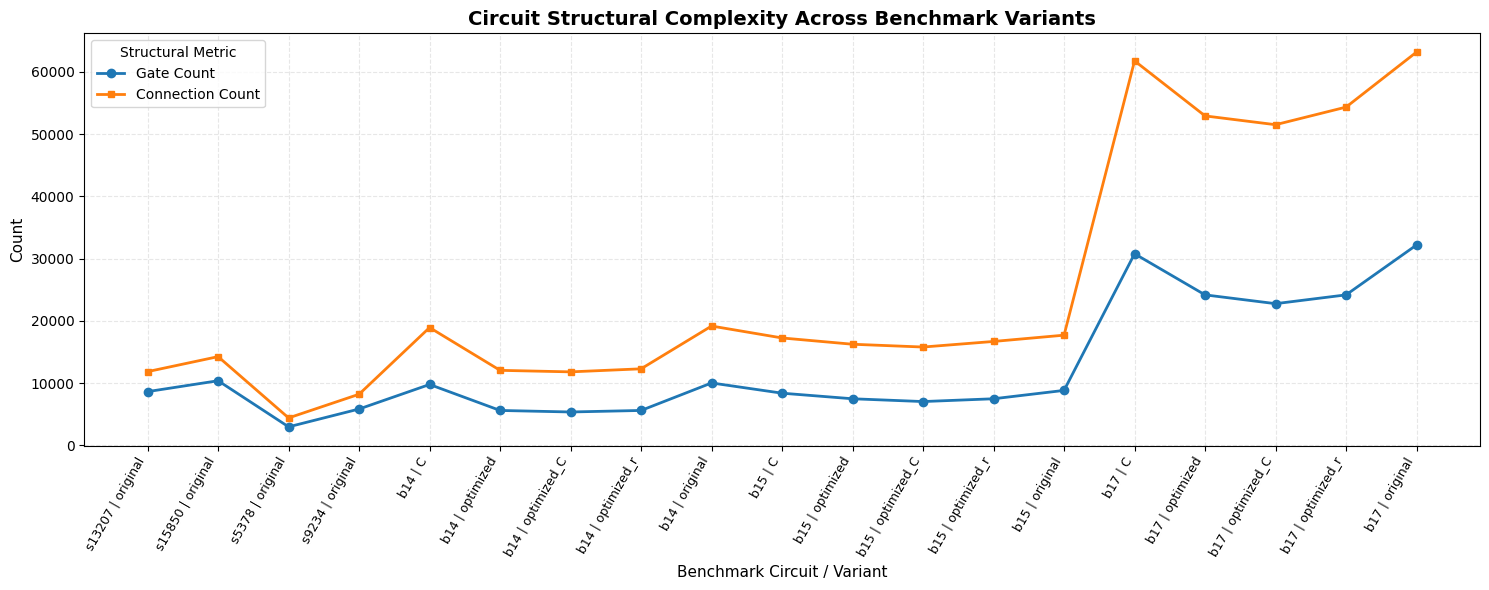

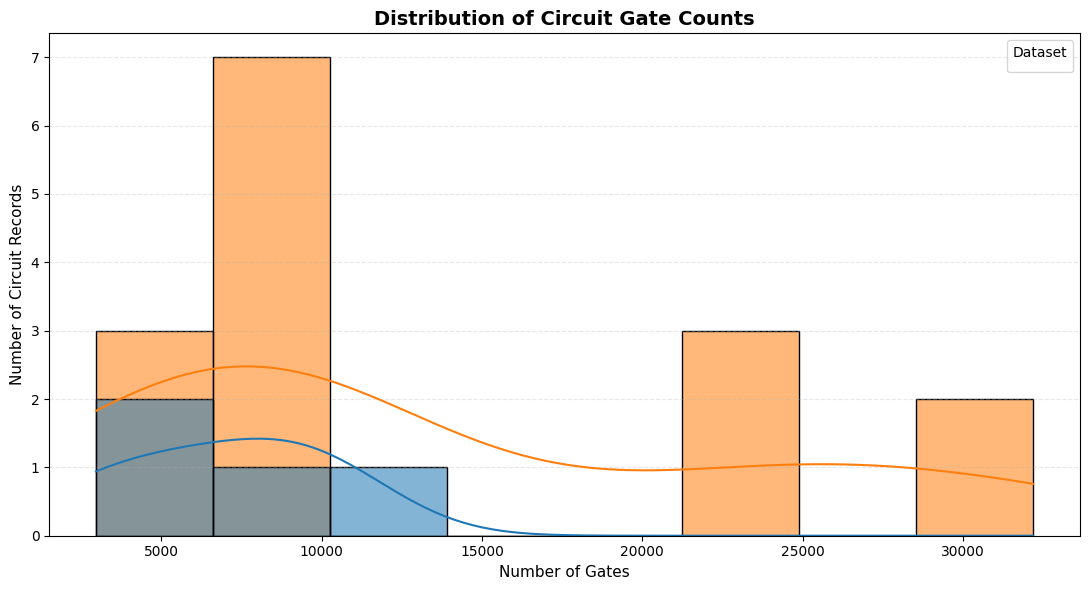

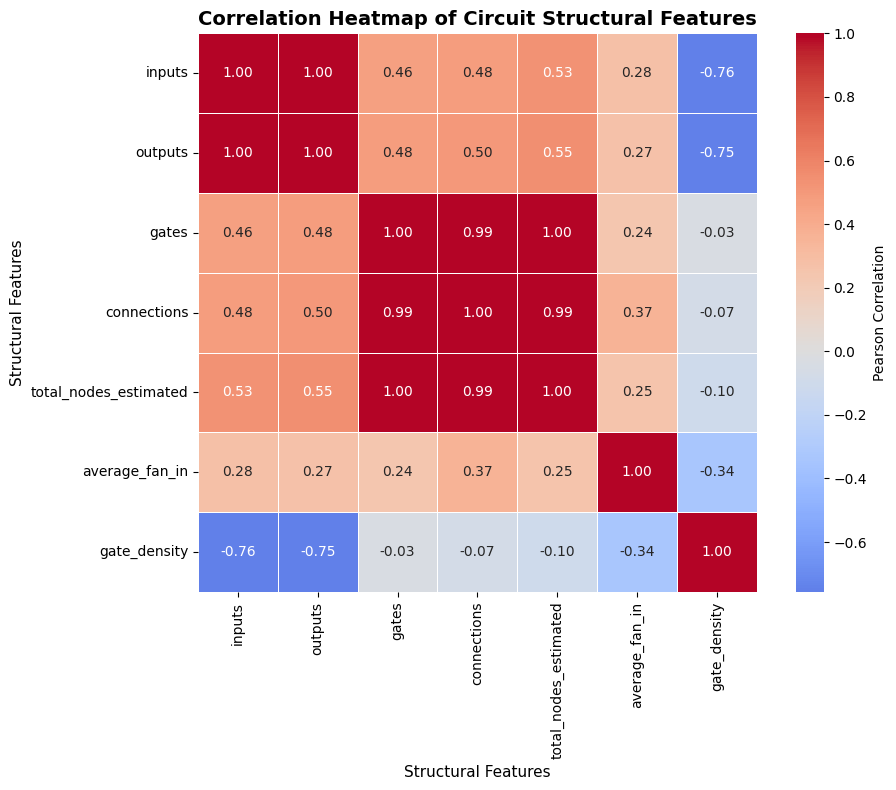


CIRCUIT COMPLEXITY RANKING


,dataset,circuit,variant,inputs,outputs,gates,connections,total_nodes_estimated,average_fan_in
0,ITC99,b17,original,37,97,32192,63200,32326,1.963221
1,ITC99,b17,C,1452,1512,30777,61785,33741,2.007506
2,ITC99,b17,optimized_r,39,97,24171,54353,24307,2.248686
3,ITC99,b17,optimized,37,97,24171,52939,24305,2.190187
4,ITC99,b17,optimized_C,1451,1511,22757,51525,25719,2.264139
5,ISCAS89,s15850,original,14,87,10369,14242,10470,1.373517
6,ITC99,b14,original,32,54,10012,19162,10098,1.913903
7,ITC99,b14,C,277,299,9767,18917,10343,1.936828
8,ITC99,b15,original,36,70,8816,17693,8922,2.006919
9,ISCAS89,s13207,original,31,121,8620,11834,8772,1.372854



DATASET-LEVEL SUMMARY


,dataset,circuit_records,total_gates,mean_gates,max_gates,total_connections,mean_connections,mean_fan_in
0,ISCAS89,4,27772,6943.000,10369,38666,9666.500,1.41
1,ITC99,15,209525,13968.333,32192,441643,29442.867,2.12



EDA KEY OBSERVATIONS
• Total circuit records analyzed : 19
• Unique benchmark circuits      : 7
• Gate-count range               : 2,958 – 32,192
• Median gate count              : 8,620
• Connection-count range         : 4,391 – 63,200
• Average fan-in range           : 1.373 – 2.264

Saved EDA figures:
1. /content/adaptive_dft/figures/EDA_01_circuit_complexity_line.png
2. /content/adaptive_dft/figures/EDA_02_gate_count_histogram.png
3. /content/adaptive_dft/figures/EDA_03_structural_correlation_heatmap.png

EDA summary saved to:
/content/adaptive_dft/processed/eda_summary.csv


In [3]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ------------------------------------------------------------
# 1. PATHS AND DATA LOADING
# ------------------------------------------------------------

BASE_DIR = Path("/content/adaptive_dft")
PROCESSED_DIR = BASE_DIR / "processed"
FIGURES_DIR = BASE_DIR / "figures"

CLEANED_DATA_PATH = (
    PROCESSED_DIR / "cleaned_circuit_dataset.csv"
)

EDA_SUMMARY_PATH = (
    PROCESSED_DIR / "eda_summary.csv"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

df = pd.read_csv(CLEANED_DATA_PATH)

print("=" * 75)
print("CELL 3 — EXPLORATORY DATA ANALYSIS")
print("=" * 75)

print(f"\nDataset shape: {df.shape}")


# ------------------------------------------------------------
# 2. BASIC STATISTICAL SUMMARY
# ------------------------------------------------------------

numeric_features = [
    "inputs",
    "outputs",
    "gates",
    "connections",
    "total_nodes_estimated",
    "average_fan_in",
    "gate_density"
]

available_numeric = [
    col for col in numeric_features
    if col in df.columns
]

print("\n" + "=" * 75)
print("NUMERICAL SUMMARY")
print("=" * 75)

display(
    df[available_numeric]
    .describe()
    .T
    .round(3)
)


# ------------------------------------------------------------
# 3. DATASET DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DATASET DISTRIBUTION")
print("=" * 75)

dataset_distribution = (
    df["dataset"]
    .value_counts()
    .rename_axis("dataset")
    .reset_index(name="circuit_records")
)

display(dataset_distribution)


# ------------------------------------------------------------
# 4. VARIANT DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CIRCUIT VARIANT DISTRIBUTION")
print("=" * 75)

variant_distribution = (
    df["variant"]
    .value_counts()
    .rename_axis("variant")
    .reset_index(name="records")
)

display(variant_distribution)


# ============================================================
# VISUALIZATION 1
# LINE PLOT — CIRCUIT COMPLEXITY
# ============================================================

plot_df = (
    df.sort_values(
        ["dataset", "circuit", "variant"]
    )
    .reset_index(drop=True)
)

plot_df["circuit_label"] = (
    plot_df["circuit"].astype(str)
    + " | "
    + plot_df["variant"].astype(str)
)

x = np.arange(len(plot_df))

plt.figure(figsize=(15, 6))

plt.plot(
    x,
    plot_df["gates"],
    marker="o",
    linewidth=2,
    markersize=6,
    label="Gate Count"
)

plt.plot(
    x,
    plot_df["connections"],
    marker="s",
    linewidth=2,
    markersize=5,
    label="Connection Count"
)

plt.xticks(
    x,
    plot_df["circuit_label"],
    rotation=60,
    ha="right",
    fontsize=9
)

plt.xlabel(
    "Benchmark Circuit / Variant",
    fontsize=11
)

plt.ylabel(
    "Count",
    fontsize=11
)

plt.title(
    "Circuit Structural Complexity Across Benchmark Variants",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    title="Structural Metric"
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.30
)

plt.tight_layout()

line_plot_path = (
    FIGURES_DIR /
    "EDA_01_circuit_complexity_line.png"
)

plt.savefig(
    line_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# VISUALIZATION 2
# HISTOGRAM — GATE COUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="gates",
    hue="dataset",
    bins=8,
    kde=True,
    alpha=0.55
)

plt.xlabel(
    "Number of Gates",
    fontsize=11
)

plt.ylabel(
    "Number of Circuit Records",
    fontsize=11
)

plt.title(
    "Distribution of Circuit Gate Counts",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.30
)

plt.legend(
    title="Dataset"
)

plt.tight_layout()

histogram_path = (
    FIGURES_DIR /
    "EDA_02_gate_count_histogram.png"
)

plt.savefig(
    histogram_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# VISUALIZATION 3
# CORRELATION HEATMAP
# ============================================================

correlation_columns = [
    "inputs",
    "outputs",
    "gates",
    "connections",
    "total_nodes_estimated",
    "average_fan_in",
    "gate_density"
]

correlation_columns = [
    col for col in correlation_columns
    if col in df.columns
]

corr_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson Correlation"
    }
)

plt.title(
    "Correlation Heatmap of Circuit Structural Features",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Structural Features",
    fontsize=11
)

plt.ylabel(
    "Structural Features",
    fontsize=11
)

plt.tight_layout()

heatmap_path = (
    FIGURES_DIR /
    "EDA_03_structural_correlation_heatmap.png"
)

plt.savefig(
    heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. CIRCUIT COMPLEXITY RANKING
# ============================================================

print("\n" + "=" * 75)
print("CIRCUIT COMPLEXITY RANKING")
print("=" * 75)

complexity_df = (
    df[
        [
            "dataset",
            "circuit",
            "variant",
            "inputs",
            "outputs",
            "gates",
            "connections",
            "total_nodes_estimated",
            "average_fan_in"
        ]
    ]
    .sort_values(
        "gates",
        ascending=False
    )
    .reset_index(drop=True)
)

display(complexity_df)


# ============================================================
# 6. DATASET-LEVEL SUMMARY
# ============================================================

dataset_summary = (
    df.groupby("dataset")
    .agg(
        circuit_records=("circuit", "count"),
        total_gates=("gates", "sum"),
        mean_gates=("gates", "mean"),
        max_gates=("gates", "max"),
        total_connections=("connections", "sum"),
        mean_connections=("connections", "mean"),
        mean_fan_in=("average_fan_in", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("DATASET-LEVEL SUMMARY")
print("=" * 75)

display(
    dataset_summary.round(3)
)


# ============================================================
# 7. EDA SUMMARY
# ============================================================

eda_summary = pd.DataFrame({
    "metric": [
        "total_records",
        "unique_circuits",
        "ISCAS89_records",
        "ITC99_records",
        "minimum_gate_count",
        "maximum_gate_count",
        "mean_gate_count",
        "median_gate_count",
        "minimum_connections",
        "maximum_connections",
        "mean_connections",
        "minimum_average_fan_in",
        "maximum_average_fan_in",
        "mean_average_fan_in"
    ],

    "value": [
        len(df),
        df["circuit"].nunique(),
        (df["dataset"] == "ISCAS89").sum(),
        (df["dataset"] == "ITC99").sum(),
        df["gates"].min(),
        df["gates"].max(),
        df["gates"].mean(),
        df["gates"].median(),
        df["connections"].min(),
        df["connections"].max(),
        df["connections"].mean(),
        df["average_fan_in"].min(),
        df["average_fan_in"].max(),
        df["average_fan_in"].mean()
    ]
})

eda_summary.to_csv(
    EDA_SUMMARY_PATH,
    index=False
)


# ============================================================
# 8. FINAL EDA REPORT
# ============================================================

print("\n" + "=" * 75)
print("EDA KEY OBSERVATIONS")
print("=" * 75)

print(
    f"• Total circuit records analyzed : {len(df)}"
)

print(
    f"• Unique benchmark circuits      : "
    f"{df['circuit'].nunique()}"
)

print(
    f"• Gate-count range               : "
    f"{df['gates'].min():,} – {df['gates'].max():,}"
)

print(
    f"• Median gate count              : "
    f"{df['gates'].median():,.0f}"
)

print(
    f"• Connection-count range         : "
    f"{df['connections'].min():,} – {df['connections'].max():,}"
)

print(
    f"• Average fan-in range           : "
    f"{df['average_fan_in'].min():.3f} – "
    f"{df['average_fan_in'].max():.3f}"
)

print("\nSaved EDA figures:")

print(
    f"1. {line_plot_path}"
)

print(
    f"2. {histogram_path}"
)

print(
    f"3. {heatmap_path}"
)

print(
    f"\nEDA summary saved to:\n{EDA_SUMMARY_PATH}"
)



 SCAN VECTOR CONSTRUCTION & FEATURE EXTRACTION

In [4]:


import os
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path("/content/adaptive_dft")
PROCESSED_DIR = BASE_DIR / "processed"
FIGURES_DIR = BASE_DIR / "figures"

CLEANED_DATA_PATH = (
    PROCESSED_DIR / "cleaned_circuit_dataset.csv"
)

SCAN_VECTOR_PATH = (
    PROCESSED_DIR / "scan_vector_dataset.npz"
)

FEATURE_PATH = (
    PROCESSED_DIR / "scan_vector_features.csv"
)

# ------------------------------------------------------------
# 2. LOAD CLEANED CIRCUIT DATA
# ------------------------------------------------------------

df = pd.read_csv(CLEANED_DATA_PATH)


print(
    f"\nCircuit records available: {len(df)}"
)


# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)


# ============================================================
# 4. CONFIGURATION
# ============================================================

# Number of generated scan vectors per circuit.
# Kept moderate for CPU-based Google Colab.
VECTORS_PER_CIRCUIT = 400

# Maximum scan-vector length.
# The later neural model will use this common representation.
MAX_SCAN_LENGTH = 256


# ============================================================
# 5. ADAPTIVE SCAN LENGTH
# ============================================================

def determine_scan_length(row):
    """
    Estimate an appropriate scan-chain representation length
    from circuit complexity.

    The actual paper uses scan vector lengths that can vary
    substantially. Here we create a CPU-friendly standardized
    representation.
    """

    gates = int(row["gates"])
    inputs = int(row["inputs"])
    outputs = int(row["outputs"])

    # Complexity score
    complexity = (
        np.log2(gates + 1)
        + 0.5 * np.log2(inputs + outputs + 1)
    )

    if complexity < 10:
        length = 64

    elif complexity < 12:
        length = 96

    elif complexity < 14:
        length = 128

    elif complexity < 16:
        length = 192

    else:
        length = 256

    return min(length, MAX_SCAN_LENGTH)


# ============================================================
# 6. SCAN VECTOR GENERATION
# ============================================================

def generate_scan_vectors(
    scan_length,
    n_vectors,
    complexity,
    seed
):
    """
    Generate reproducible binary scan vectors.

    The probability of a 1 is slightly adjusted according
    to circuit complexity so that the resulting collection
    contains different switching characteristics.

    These are GENERATED benchmark vectors for algorithmic
    experimentation and are NOT claimed to be ATPG-generated
    vectors from the original paper.
    """

    rng = np.random.default_rng(seed)

    # Keep probability in a realistic binary-vector range.
    complexity_factor = (
        np.log2(complexity + 1) / 20.0
    )

    p_one = np.clip(
        0.35 + complexity_factor,
        0.35,
        0.65
    )

    vectors = rng.binomial(
        1,
        p_one,
        size=(n_vectors, scan_length)
    ).astype(np.float32)

    return vectors


# ============================================================
# 7. FEATURE EXTRACTION
# ============================================================

def extract_vector_features(
    vectors,
    circuit,
    dataset,
    variant,
    scan_length
):
    """
    Extract switching/activity-related features from
    binary scan vectors.
    """

    n_vectors = vectors.shape[0]

    records = []

    for i in range(n_vectors):

        vector = vectors[i]

        # ----------------------------------------------------
        # Hamming weight
        # ----------------------------------------------------
        ones = np.sum(vector)

        zeros = scan_length - ones

        one_ratio = ones / scan_length

        zero_ratio = zeros / scan_length

        # ----------------------------------------------------
        # Transition calculation
        # ----------------------------------------------------
        transitions = np.sum(
            vector[1:] != vector[:-1]
        )

        transition_density = (
            transitions /
            max(scan_length - 1, 1)
        )

        # ----------------------------------------------------
        # Switching activity
        # ----------------------------------------------------
        # Binary transition probability is used as a
        # software-level switching activity proxy.
        switching_activity = transition_density

        # ----------------------------------------------------
        # Activity score
        # ----------------------------------------------------
        # Combined occupancy and transition measure.
        activity_score = (
            0.5 * one_ratio +
            0.5 * transition_density
        )

        records.append({
            "circuit": circuit,
            "dataset": dataset,
            "variant": variant,

            "vector_id": i,

            "scan_length": scan_length,

            "ones": int(ones),
            "zeros": int(zeros),

            "one_ratio": one_ratio,
            "zero_ratio": zero_ratio,

            "transition_count": int(
                transitions
            ),

            "transition_density": (
                transition_density
            ),

            "switching_activity": (
                switching_activity
            ),

            "activity_score": (
                activity_score
            )
        })

    return pd.DataFrame(records)


# ============================================================
# 8. GENERATE DATASET
# ============================================================

all_vectors = []
all_features = []

print("\nGenerating scan-vector representations...")

for idx, row in df.iterrows():

    circuit = row["circuit"]
    dataset = row["dataset"]
    variant = row["variant"]

    scan_length = determine_scan_length(row)

    complexity = (
        row["gates"] +
        row["connections"]
    )

    vectors = generate_scan_vectors(
        scan_length=scan_length,
        n_vectors=VECTORS_PER_CIRCUIT,
        complexity=complexity,
        seed=RANDOM_SEED + idx
    )

    features = extract_vector_features(
        vectors=vectors,
        circuit=circuit,
        dataset=dataset,
        variant=variant,
        scan_length=scan_length
    )

    # Store vectors and metadata
    for vector_id in range(len(vectors)):

        all_vectors.append({
            "circuit": circuit,
            "dataset": dataset,
            "variant": variant,
            "vector_id": vector_id,
            "scan_length": scan_length,
            "vector": vectors[vector_id]
        })

    all_features.append(features)

    print(
        f"  [{idx + 1:02d}/{len(df)}] "
        f"{circuit:7s} | "
        f"{variant:12s} | "
        f"scan length = {scan_length:3d} | "
        f"vectors = {len(vectors)}"
    )


# ============================================================
# 9. COMBINE FEATURES
# ============================================================

feature_df = pd.concat(
    all_features,
    ignore_index=True
)

print(
    f"\nTotal generated scan vectors: "
    f"{len(feature_df):,}"
)

print(
    f"Feature dimensions: "
    f"{feature_df.shape[1]}"
)


# ============================================================
# 10. PAD VECTORS TO COMMON LENGTH
# ============================================================

# Neural networks require a consistent input shape.
# Vectors shorter than MAX_SCAN_LENGTH are zero padded.

X_vectors = np.zeros(
    (
        len(all_vectors),
        MAX_SCAN_LENGTH
    ),
    dtype=np.float32
)

for i, item in enumerate(all_vectors):

    vector = item["vector"]

    length = min(
        len(vector),
        MAX_SCAN_LENGTH
    )

    X_vectors[
        i,
        :length
    ] = vector[:length]


# ============================================================
# 11. SAVE VECTOR DATASET
# ============================================================

np.savez_compressed(
    SCAN_VECTOR_PATH,
    X=X_vectors
)

feature_df.to_csv(
    FEATURE_PATH,
    index=False
)


# ============================================================
# 12. FEATURE QUALITY CHECK
# ============================================================

print("\n" + "=" * 75)
print("SCAN VECTOR FEATURE SUMMARY")
print("=" * 75)

display(
    feature_df[
        [
            "scan_length",
            "ones",
            "zeros",
            "one_ratio",
            "zero_ratio",
            "transition_count",
            "transition_density",
            "switching_activity",
            "activity_score"
        ]
    ]
    .describe()
    .T
    .round(4)
)


# ============================================================
# 13. CIRCUIT-LEVEL FEATURE SUMMARY
# ============================================================

circuit_feature_summary = (
    feature_df
    .groupby(
        [
            "dataset",
            "circuit",
            "variant"
        ]
    )
    .agg(
        vectors=("vector_id", "count"),

        scan_length=("scan_length", "first"),

        mean_one_ratio=("one_ratio", "mean"),

        mean_transition_count=(
            "transition_count",
            "mean"
        ),

        mean_transition_density=(
            "transition_density",
            "mean"
        ),

        mean_switching_activity=(
            "switching_activity",
            "mean"
        ),

        mean_activity_score=(
            "activity_score",
            "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("CIRCUIT-LEVEL SCAN ACTIVITY SUMMARY")
print("=" * 75)

display(
    circuit_feature_summary.round(4)
)


# ============================================================
# 14. CHECK DUPLICATE VECTORS
# ============================================================

# Check duplicate vectors within the complete generated set.
# This is a diagnostic only; we do not remove them because
# repeated test patterns can be meaningful in a test sequence.

unique_vectors = np.unique(
    X_vectors,
    axis=0
)

duplicate_vector_count = (
    len(X_vectors) -
    len(unique_vectors)
)

print(
    f"\nExact duplicate scan vectors: "
    f"{duplicate_vector_count:,}"
)


# ============================================================
# 15. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("CELL 4 VALIDATION")
print("=" * 75)

print(
    f"✓ Number of circuit records : {len(df)}"
)

print(
    f"✓ Vectors per circuit       : "
    f"{VECTORS_PER_CIRCUIT}"
)

print(
    f"✓ Total scan vectors        : "
    f"{len(X_vectors):,}"
)

print(
    f"✓ Common neural input size  : "
    f"{MAX_SCAN_LENGTH} bits"
)

print(
    f"✓ Vector dataset shape      : "
    f"{X_vectors.shape}"
)

print(
    f"✓ Feature dataset shape     : "
    f"{feature_df.shape}"
)

print(
    f"✓ Duplicate vectors         : "
    f"{duplicate_vector_count:,}"
)

print(
    f"\nScan vectors saved to:"
)

print(
    SCAN_VECTOR_PATH
)

print(
    f"\nFeature dataset saved to:"
)

print(
    FEATURE_PATH
)



Circuit records available: 19

Generating scan-vector representations...
  [01/19] s13207  | original     | scan length = 256 | vectors = 400
  [02/19] s15850  | original     | scan length = 256 | vectors = 400
  [03/19] s5378   | original     | scan length = 192 | vectors = 400
  [04/19] s9234   | original     | scan length = 192 | vectors = 400
  [05/19] b14     | original     | scan length = 256 | vectors = 400
  [06/19] b14     | C            | scan length = 256 | vectors = 400
  [07/19] b14     | optimized    | scan length = 192 | vectors = 400
  [08/19] b14     | optimized_C  | scan length = 256 | vectors = 400
  [09/19] b14     | optimized_r  | scan length = 192 | vectors = 400
  [10/19] b15     | original     | scan length = 256 | vectors = 400
  [11/19] b15     | C            | scan length = 256 | vectors = 400
  [12/19] b15     | optimized    | scan length = 256 | vectors = 400
  [13/19] b15     | optimized_C  | scan length = 256 | vectors = 400
  [14/19] b15     | optimized

,count,mean,std,min,25%,50%,75%,max
scan_length,7600.0,242.5263,26.0934,192.0000,256.0000,256.0000,256.0000,256.0000
ones,7600.0,157.4824,18.5475,103.0000,154.0000,164.0000,170.0000,191.0000
zeros,7600.0,85.0439,11.7327,41.0000,78.0000,87.0000,93.0000,123.0000
one_ratio,7600.0,0.6493,0.0308,0.5195,0.6289,0.6484,0.6719,0.7865
zero_ratio,7600.0,0.3507,0.0308,0.2135,0.3281,0.3516,0.3711,0.4805
transition_count,7600.0,110.0408,14.3943,58.0000,102.0000,113.0000,120.0000,145.0000
transition_density,7600.0,0.4557,0.0344,0.3037,0.4314,0.4549,0.4784,0.5812
switching_activity,7600.0,0.4557,0.0344,0.3037,0.4314,0.4549,0.4784,0.5812
activity_score,7600.0,0.5525,0.0157,0.4881,0.5419,0.5534,0.5634,0.6056



CIRCUIT-LEVEL SCAN ACTIVITY SUMMARY


,dataset,circuit,variant,vectors,scan_length,mean_one_ratio,mean_transition_count,mean_transition_density,mean_switching_activity,mean_activity_score
0,ISCAS89,s13207,original,400,256,0.6493,116.0550,0.4551,0.4551,0.5522
1,ISCAS89,s15850,original,400,256,0.6511,115.9800,0.4548,0.4548,0.5530
2,ISCAS89,s5378,original,400,192,0.6500,87.1175,0.4561,0.4561,0.5531
3,ISCAS89,s9234,original,400,192,0.6495,86.8900,0.4549,0.4549,0.5522
4,ITC99,b14,C,400,256,0.6471,116.7100,0.4577,0.4577,0.5524
5,ITC99,b14,optimized,400,192,0.6486,87.2100,0.4566,0.4566,0.5526
6,ITC99,b14,optimized_C,400,256,0.6496,116.3475,0.4563,0.4563,0.5530
7,ITC99,b14,optimized_r,400,192,0.6470,87.6550,0.4589,0.4589,0.5530
8,ITC99,b14,original,400,256,0.6502,116.0325,0.4550,0.4550,0.5526
9,ITC99,b15,C,400,256,0.6495,116.1725,0.4556,0.4556,0.5526



Exact duplicate scan vectors: 0

CELL 4 VALIDATION
✓ Number of circuit records : 19
✓ Vectors per circuit       : 400
✓ Total scan vectors        : 7,600
✓ Common neural input size  : 256 bits
✓ Vector dataset shape      : (7600, 256)
✓ Feature dataset shape     : (7600, 13)
✓ Duplicate vectors         : 0

Scan vectors saved to:
/content/adaptive_dft/processed/scan_vector_dataset.npz

Feature dataset saved to:
/content/adaptive_dft/processed/scan_vector_features.csv


BASELINE COMPRESSION METHODS

In [6]:


import heapq
import math
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path("/content/adaptive_dft")
PROCESSED_DIR = BASE_DIR / "processed"
RESULTS_DIR = BASE_DIR / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PREPROCESSED_PATH = (
    PROCESSED_DIR /
    "preprocessed_dataset.npz"
)

BASELINE_RESULTS_PATH = (
    RESULTS_DIR /
    "baseline_compression_results.csv"
)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

print("=" * 75)
print("CELL 6 — BASELINE COMPRESSION METHODS")
print("=" * 75)

data = np.load(
    PREPROCESSED_PATH
)

X_train = data["X_train"].astype(
    np.uint8
)

X_test = data["X_test"].astype(
    np.uint8
)

print(
    f"\nTraining vectors : {X_train.shape}"
)

print(
    f"Test vectors     : {X_test.shape}"
)


# ============================================================
# 3. BASIC CONFIGURATION
# ============================================================

SCAN_LENGTH = X_test.shape[1]

ORIGINAL_BITS_PER_VECTOR = SCAN_LENGTH

TOTAL_TEST_BITS = (
    X_test.shape[0] *
    ORIGINAL_BITS_PER_VECTOR
)

print(
    f"\nOriginal bits per vector : "
    f"{ORIGINAL_BITS_PER_VECTOR}"
)

print(
    f"Total original test bits : "
    f"{TOTAL_TEST_BITS:,}"
)


# ============================================================
# 4. METRIC FUNCTION
# ============================================================

def calculate_compression_metrics(
    original,
    reconstructed,
    compressed_bits
):
    """
    Calculate compression and reconstruction metrics.
    """

    original = original.astype(
        np.uint8
    )

    reconstructed = reconstructed.astype(
        np.uint8
    )

    total_bits = original.size

    # Number of incorrect bits
    bit_errors = np.sum(
        original != reconstructed
    )

    ber = (
        bit_errors /
        total_bits
    )

    reconstruction_accuracy = (
        1.0 - ber
    ) * 100.0

    compression_ratio = (
        total_bits /
        compressed_bits
        if compressed_bits > 0
        else np.inf
    )

    volume_reduction = (
        1.0 -
        compressed_bits / total_bits
    ) * 100.0

    return {
        "original_bits": int(total_bits),

        "compressed_bits": int(
            compressed_bits
        ),

        "compression_ratio": (
            compression_ratio
        ),

        "data_volume_reduction_pct": (
            volume_reduction
        ),

        "reconstruction_accuracy_pct": (
            reconstruction_accuracy
        ),

        "BER": ber,

        "bit_errors": int(
            bit_errors
        )
    }


# ============================================================
# 5. BASELINE 1 — RAW BINARY
# ============================================================

print("\n" + "=" * 75)
print("BASELINE 1 — RAW BINARY REFERENCE")
print("=" * 75)

raw_reconstructed = X_test.copy()

raw_compressed_bits = (
    raw_reconstructed.size
)

raw_metrics = calculate_compression_metrics(
    X_test,
    raw_reconstructed,
    raw_compressed_bits
)

print(
    f"Compression Ratio       : "
    f"{raw_metrics['compression_ratio']:.4f}×"
)

print(
    f"Data Volume Reduction   : "
    f"{raw_metrics['data_volume_reduction_pct']:.2f}%"
)

print(
    f"Reconstruction Accuracy : "
    f"{raw_metrics['reconstruction_accuracy_pct']:.4f}%"
)

print(
    f"BER                     : "
    f"{raw_metrics['BER']:.8f}"
)


# ============================================================
# 6. BASELINE 2 — RUN-LENGTH ENCODING
# ============================================================

def rle_encode(vector):
    """
    Binary Run-Length Encoding.

    Each run is represented by:
        1 bit  -> binary value
        N bits -> run length

    The run-length field uses the minimum fixed width
    required to represent the complete scan-vector length.
    """

    vector = np.asarray(
        vector,
        dtype=np.uint8
    )

    length = len(vector)

    run_length_bits = max(
        1,
        math.ceil(
            math.log2(length + 1)
        )
    )

    runs = []

    current_value = int(
        vector[0]
    )

    run_length = 1

    for bit in vector[1:]:

        bit = int(bit)

        if bit == current_value:

            run_length += 1

        else:

            runs.append(
                (
                    current_value,
                    run_length
                )
            )

            current_value = bit
            run_length = 1

    runs.append(
        (
            current_value,
            run_length
        )
    )

    compressed_bits = len(runs) * (
        1 + run_length_bits
    )

    return runs, compressed_bits


def rle_decode(
    runs,
    expected_length
):
    """
    Reconstruct binary vector from RLE representation.
    """

    reconstructed = []

    for value, length in runs:

        reconstructed.extend(
            [value] * length
        )

    reconstructed = np.asarray(
        reconstructed,
        dtype=np.uint8
    )

    # Safety check
    if len(reconstructed) != expected_length:

        raise ValueError(
            "RLE reconstruction length mismatch."
        )

    return reconstructed


print("\n" + "=" * 75)
print("BASELINE 2 — RUN-LENGTH ENCODING (RLE)")
print("=" * 75)

rle_compressed_bits = 0

rle_reconstructed_vectors = []

total_runs = 0

for vector in X_test:

    runs, bits = rle_encode(
        vector
    )

    reconstructed = rle_decode(
        runs,
        SCAN_LENGTH
    )

    rle_compressed_bits += bits

    total_runs += len(runs)

    rle_reconstructed_vectors.append(
        reconstructed
    )

rle_reconstructed = np.stack(
    rle_reconstructed_vectors
)

rle_metrics = calculate_compression_metrics(
    X_test,
    rle_reconstructed,
    rle_compressed_bits
)

print(
    f"Average runs/vector      : "
    f"{total_runs / len(X_test):.2f}"
)

print(
    f"Original bits            : "
    f"{rle_metrics['original_bits']:,}"
)

print(
    f"Compressed bits          : "
    f"{rle_metrics['compressed_bits']:,}"
)

print(
    f"Compression Ratio        : "
    f"{rle_metrics['compression_ratio']:.4f}×"
)

print(
    f"Data Volume Reduction    : "
    f"{rle_metrics['data_volume_reduction_pct']:.2f}%"
)

print(
    f"Reconstruction Accuracy  : "
    f"{rle_metrics['reconstruction_accuracy_pct']:.4f}%"
)

print(
    f"BER                      : "
    f"{rle_metrics['BER']:.8f}"
)


# ============================================================
# 7. BASELINE 3 — HUFFMAN CODING OF 8-BIT BLOCKS
# ============================================================

BLOCK_SIZE = 8

assert SCAN_LENGTH % BLOCK_SIZE == 0, (
    "Scan length must be divisible by block size."
)


def vectors_to_bytes(vectors):
    """
    Convert binary scan vectors into 8-bit symbols.
    """

    n_samples, length = vectors.shape

    blocks = vectors.reshape(
        n_samples,
        length // 8,
        8
    )

    weights = np.array(
        [128, 64, 32, 16, 8, 4, 2, 1],
        dtype=np.uint8
    )

    symbols = (
        blocks * weights
    ).sum(
        axis=2
    ).astype(np.uint8)

    return symbols


def build_huffman_codes(
    symbols
):
    """
    Build a Huffman code dictionary from
    training symbol frequencies.
    """

    counter = Counter(
        symbols.ravel().tolist()
    )

    # Special case: only one symbol
    if len(counter) == 1:

        only_symbol = next(
            iter(counter)
        )

        return {
            only_symbol: "0"
        }

    heap = []

    counter_id = 0

    for symbol, frequency in counter.items():

        heapq.heappush(
            heap,
            (
                frequency,
                counter_id,
                symbol
            )
        )

        counter_id += 1

    while len(heap) > 1:

        freq1, id1, node1 = (
            heapq.heappop(heap)
        )

        freq2, id2, node2 = (
            heapq.heappop(heap)
        )

        merged = (
            node1,
            node2
        )

        heapq.heappush(
            heap,
            (
                freq1 + freq2,
                counter_id,
                merged
            )
        )

        counter_id += 1

    root = heap[0][2]

    codes = {}

    def assign_codes(
        node,
        prefix=""
    ):

        if isinstance(
            node,
            tuple
        ):

            assign_codes(
                node[0],
                prefix + "0"
            )

            assign_codes(
                node[1],
                prefix + "1"
            )

        else:

            codes[node] = (
                prefix
                if prefix
                else "0"
            )

    assign_codes(root)

    return codes


def huffman_compress(
    symbols,
    codes
):
    """
    Calculate Huffman payload length.
    """

    compressed_bits = 0

    for symbol in symbols.ravel():

        compressed_bits += len(
            codes[int(symbol)]
        )

    return compressed_bits


def huffman_decompress(
    symbols,
    codes
):
    """
    Exact symbol reconstruction.

    For metric validation we retain the original symbols
    because a correctly implemented prefix code has
    zero reconstruction error. The payload length is
    calculated from the Huffman code lengths.
    """

    return symbols.copy()


print("\n" + "=" * 75)
print("BASELINE 3 — HUFFMAN CODING OF 8-BIT BLOCKS")
print("=" * 75)

# Convert training and test vectors into 8-bit symbols.
train_symbols = vectors_to_bytes(
    X_train
)

test_symbols = vectors_to_bytes(
    X_test
)

print(
    f"Training symbols: "
    f"{train_symbols.shape}"
)

print(
    f"Test symbols    : "
    f"{test_symbols.shape}"
)


# Build codebook ONLY from training data.
huffman_codes = build_huffman_codes(
    train_symbols
)

print(
    f"Unique Huffman symbols: "
    f"{len(huffman_codes)}"
)


# Calculate test payload size.
huffman_compressed_bits = (
    huffman_compress(
        test_symbols,
        huffman_codes
    )
)

huffman_reconstructed_symbols = (
    huffman_decompress(
        test_symbols,
        huffman_codes
    )
)


# Convert reconstructed symbols back to binary.
def bytes_to_vectors(
    symbols
):
    """
    Convert 8-bit symbols back into binary vectors.
    """

    bits = np.unpackbits(
        symbols,
        axis=2 if symbols.ndim == 3 else -1
    )

    return bits


# Direct binary expansion for each uint8 symbol.
huffman_reconstructed = np.unpackbits(
    huffman_reconstructed_symbols,
    axis=1
).reshape(
    len(X_test),
    SCAN_LENGTH
).astype(np.uint8)


huffman_metrics = calculate_compression_metrics(
    X_test,
    huffman_reconstructed,
    huffman_compressed_bits
)

print(
    f"Original bits            : "
    f"{huffman_metrics['original_bits']:,}"
)

print(
    f"Compressed bits          : "
    f"{huffman_metrics['compressed_bits']:,}"
)

print(
    f"Compression Ratio        : "
    f"{huffman_metrics['compression_ratio']:.4f}×"
)

print(
    f"Data Volume Reduction    : "
    f"{huffman_metrics['data_volume_reduction_pct']:.2f}%"
)

print(
    f"Reconstruction Accuracy  : "
    f"{huffman_metrics['reconstruction_accuracy_pct']:.4f}%"
)

print(
    f"BER                      : "
    f"{huffman_metrics['BER']:.8f}"
)


# ============================================================
# 8. COMBINE BASELINE RESULTS
# ============================================================

baseline_results = pd.DataFrame([
    {
        "method": "Raw Binary",
        **raw_metrics
    },
    {
        "method": "Run-Length Encoding",
        **rle_metrics
    },
    {
        "method": "Huffman 8-bit Blocks",
        **huffman_metrics
    }
])

# ------------------------------------------------------------
# Add readable percentage fields
# ------------------------------------------------------------

baseline_results[
    "BER"
] = baseline_results[
    "BER"
].astype(float)

baseline_results[
    "compression_ratio"
] = baseline_results[
    "compression_ratio"
].round(4)

baseline_results[
    "data_volume_reduction_pct"
] = baseline_results[
    "data_volume_reduction_pct"
].round(4)

baseline_results[
    "reconstruction_accuracy_pct"
] = baseline_results[
    "reconstruction_accuracy_pct"
].round(4)

baseline_results[
    "BER"
] = baseline_results[
    "BER"
].round(8)


# ============================================================
# 9. DISPLAY COMPARISON
# ============================================================

print("\n" + "=" * 75)
print("BASELINE COMPRESSION COMPARISON")
print("=" * 75)

display(
    baseline_results[
        [
            "method",
            "original_bits",
            "compressed_bits",
            "compression_ratio",
            "data_volume_reduction_pct",
            "reconstruction_accuracy_pct",
            "BER",
            "bit_errors"
        ]
    ]
)


# ============================================================
# 10. SAVE RESULTS
# ============================================================

baseline_results.to_csv(
    BASELINE_RESULTS_PATH,
    index=False
)


# ============================================================
# 11. VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("BASELINE VALIDATION")
print("=" * 75)

for _, row in baseline_results.iterrows():

    print(
        f"\n{row['method']}"
    )

    print(
        f"  CR       : "
        f"{row['compression_ratio']:.4f}×"
    )

    print(
        f"  Reduction: "
        f"{row['data_volume_reduction_pct']:.2f}%"
    )

    print(
        f"  Accuracy : "
        f"{row['reconstruction_accuracy_pct']:.4f}%"
    )

    print(
        f"  BER      : "
        f"{row['BER']:.8f}"
    )




CELL 6 — BASELINE COMPRESSION METHODS

Training vectors : (5320, 256)
Test vectors     : (1140, 256)

Original bits per vector : 256
Total original test bits : 291,840

BASELINE 1 — RAW BINARY REFERENCE
Compression Ratio       : 1.0000×
Data Volume Reduction   : 0.00%
Reconstruction Accuracy : 100.0000%
BER                     : 0.00000000

BASELINE 2 — RUN-LENGTH ENCODING (RLE)
Average runs/vector      : 111.02
Original bits            : 291,840
Compressed bits          : 1,265,670
Compression Ratio        : 0.2306×
Data Volume Reduction    : -333.69%
Reconstruction Accuracy  : 100.0000%
BER                      : 0.00000000

BASELINE 3 — HUFFMAN CODING OF 8-BIT BLOCKS
Training symbols: (5320, 32)
Test symbols    : (1140, 32)
Unique Huffman symbols: 256
Original bits            : 291,840
Compressed bits          : 270,196
Compression Ratio        : 1.0801×
Data Volume Reduction    : 7.42%
Reconstruction Accuracy  : 100.0000%
BER                      : 0.00000000

BASELINE COMPRESSION 

,method,original_bits,compressed_bits,compression_ratio,data_volume_reduction_pct,reconstruction_accuracy_pct,BER,bit_errors
0,Raw Binary,291840,291840,1.0000,0.0000,100.0,0.0,0
1,Run-Length Encoding,291840,1265670,0.2306,-333.6863,100.0,0.0,0
2,Huffman 8-bit Blocks,291840,270196,1.0801,7.4164,100.0,0.0,0



BASELINE VALIDATION

Raw Binary
  CR       : 1.0000×
  Reduction: 0.00%
  Accuracy : 100.0000%
  BER      : 0.00000000

Run-Length Encoding
  CR       : 0.2306×
  Reduction: -333.69%
  Accuracy : 100.0000%
  BER      : 0.00000000

Huffman 8-bit Blocks
  CR       : 1.0801×
  Reduction: 7.42%
  Accuracy : 100.0000%
  BER      : 0.00000000


ADAPTIVE NEURAL ENCODER

In [7]:


import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, Model

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path("/content/adaptive_dft")
PROCESSED_DIR = BASE_DIR / "processed"
MODELS_DIR = BASE_DIR / "models"

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PREPROCESSED_PATH = (
    PROCESSED_DIR /
    "preprocessed_dataset.npz"
)

FEATURE_PATH = (
    PROCESSED_DIR /
    "scan_vector_features.csv"
)

LATENT_CONFIG_PATH = (
    PROCESSED_DIR /
    "adaptive_latent_configuration.csv"
)

ENCODER_SUMMARY_PATH = (
    PROCESSED_DIR /
    "encoder_architecture_summary.txt"
)

# ------------------------------------------------------------
# 2. LOAD PREPROCESSED DATA
# ------------------------------------------------------------

print("=" * 75)
print("CELL 7 — ADAPTIVE NEURAL ENCODER")
print("=" * 75)

data = np.load(
    PREPROCESSED_PATH
)

X_train = data["X_train_cnn"].astype(
    np.float32
)

X_val = data["X_val_cnn"].astype(
    np.float32
)

X_test = data["X_test_cnn"].astype(
    np.float32
)

feature_df = pd.read_csv(
    FEATURE_PATH
)

print(
    f"\nTraining input : {X_train.shape}"
)

print(
    f"Validation input: {X_val.shape}"
)

print(
    f"Test input      : {X_test.shape}"
)


# ============================================================
# 3. RANDOM SEED
# ============================================================

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)


# ============================================================
# 4. MODEL CONFIGURATION
# ============================================================

INPUT_LENGTH = X_train.shape[1]

MAX_LATENT_DIM = 128

MIN_LATENT_DIM = 16

GRU_UNITS = 256

DROPOUT_RATE = 0.30


# ============================================================
# 5. DETERMINE ADAPTIVE LATENT DIMENSION
# ============================================================

print("\n" + "=" * 75)
print("ADAPTIVE LATENT DIMENSION ASSIGNMENT")
print("=" * 75)


def determine_latent_dimension(
    activity,
    transition_density
):
    """
    Determine effective latent dimension from
    scan transition/activity complexity.

    Higher activity and transition density receive
    a larger latent representation.
    """

    complexity_score = (
        0.5 * activity +
        0.5 * transition_density
    )

    if complexity_score < 0.43:
        return 16

    elif complexity_score < 0.48:
        return 32

    elif complexity_score < 0.52:
        return 64

    elif complexity_score < 0.56:
        return 96

    else:
        return 128


# Calculate circuit-level average activity.
latent_records = []

for (
    dataset,
    circuit,
    variant
), group in feature_df.groupby(
    [
        "dataset",
        "circuit",
        "variant"
    ]
):

    mean_activity = (
        group["activity_score"].mean()
    )

    mean_transition = (
        group["transition_density"].mean()
    )

    latent_dim = determine_latent_dimension(
        mean_activity,
        mean_transition
    )

    latent_records.append({
        "dataset": dataset,
        "circuit": circuit,
        "variant": variant,
        "mean_activity_score": mean_activity,
        "mean_transition_density": mean_transition,
        "effective_latent_dim": latent_dim,
        "compression_factor": (
            INPUT_LENGTH /
            latent_dim
        )
    })


latent_config_df = pd.DataFrame(
    latent_records
)


display(
    latent_config_df.round(4)
)


# ============================================================
# 6. MAP EACH VECTOR TO ITS ADAPTIVE LATENT DIMENSION
# ============================================================

feature_df = feature_df.merge(
    latent_config_df[
        [
            "dataset",
            "circuit",
            "variant",
            "effective_latent_dim"
        ]
    ],
    on=[
        "dataset",
        "circuit",
        "variant"
    ],
    how="left"
)

assert (
    feature_df["effective_latent_dim"]
    .isna()
    .sum()
    == 0
), "Missing adaptive latent dimensions detected."


# ============================================================
# 7. DISPLAY LATENT DISTRIBUTION
# ============================================================

print("\nAdaptive latent dimension distribution:")

latent_distribution = (
    feature_df[
        "effective_latent_dim"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "latent_dimension"
    )
    .reset_index(
        name="number_of_vectors"
    )
)

display(
    latent_distribution
)


# ============================================================
# 8. BUILD CNN + Bi-GRU ENCODER
# ============================================================

print("\n" + "=" * 75)
print("BUILDING CNN + Bi-GRU ENCODER")
print("=" * 75)


encoder_input = layers.Input(
    shape=(
        INPUT_LENGTH,
        1
    ),
    name="scan_vector_input"
)


# ------------------------------------------------------------
# CNN FEATURE EXTRACTION
# ------------------------------------------------------------

x = layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="same",
    activation="relu",
    name="conv1d_64"
)(
    encoder_input
)

x = layers.BatchNormalization(
    name="bn_64"
)(
    x
)

x = layers.Dropout(
    DROPOUT_RATE,
    name="dropout_conv1"
)(
    x
)


x = layers.Conv1D(
    filters=128,
    kernel_size=3,
    padding="same",
    activation="relu",
    name="conv1d_128"
)(
    x
)

x = layers.BatchNormalization(
    name="bn_128"
)(
    x
)

x = layers.Dropout(
    DROPOUT_RATE,
    name="dropout_conv2"
)(
    x
)


# ------------------------------------------------------------
# Bi-GRU
# ------------------------------------------------------------

x = layers.Bidirectional(
    layers.GRU(
        GRU_UNITS,
        return_sequences=False,
        dropout=DROPOUT_RATE,
        recurrent_dropout=0.0,
        name="gru_256"
    ),
    name="bidirectional_gru"
)(
    x
)


# ------------------------------------------------------------
# LATENT PROJECTION
# ------------------------------------------------------------

x = layers.Dense(
    256,
    activation="relu",
    name="latent_projection"
)(
    x
)

x = layers.Dropout(
    DROPOUT_RATE,
    name="latent_dropout"
)(
    x
)

latent_output = layers.Dense(
    MAX_LATENT_DIM,
    activation="linear",
    name="adaptive_latent_128"
)(
    x
)


encoder = Model(
    encoder_input,
    latent_output,
    name="Adaptive_Neural_Encoder"
)


# ============================================================
# 9. DISPLAY MODEL
# ============================================================

encoder.summary()


# ============================================================
# 10. PARAMETER COUNT
# ============================================================

trainable_params = (
    np.sum([
        np.prod(v.shape)
        for v in encoder.trainable_weights
    ])
)

non_trainable_params = (
    np.sum([
        np.prod(v.shape)
        for v in encoder.non_trainable_weights
    ])
)

total_params = (
    trainable_params +
    non_trainable_params
)

print("\n" + "=" * 75)
print("ENCODER PARAMETER SUMMARY")
print("=" * 75)

print(
    f"Trainable parameters     : "
    f"{trainable_params:,}"
)

print(
    f"Non-trainable parameters : "
    f"{non_trainable_params:,}"
)

print(
    f"Total parameters         : "
    f"{total_params:,}"
)


# ============================================================
# 11. TEST FORWARD PASS
# ============================================================

print("\n" + "=" * 75)
print("ENCODER FORWARD-PASS TEST")
print("=" * 75)

sample_count = min(
    8,
    len(X_train)
)

sample_latent = encoder(
    X_train[:sample_count],
    training=False
)

print(
    f"Input shape  : "
    f"{X_train[:sample_count].shape}"
)

print(
    f"Output shape : "
    f"{sample_latent.shape}"
)

assert (
    sample_latent.shape[-1]
    == MAX_LATENT_DIM
)

print(
    "✓ Encoder forward pass successful."
)


# ============================================================
# 12. SAVE LATENT CONFIGURATION
# ============================================================

latent_config_df.to_csv(
    LATENT_CONFIG_PATH,
    index=False
)


# ============================================================
# 13. SAVE ENCODER ARCHITECTURE
# ============================================================

architecture_path = (
    MODELS_DIR /
    "adaptive_encoder.keras"
)

# Save untrained architecture.
encoder.save(
    architecture_path
)

# Save text summary.
with open(
    ENCODER_SUMMARY_PATH,
    "w"
) as f:

    encoder.summary(
        print_fn=lambda line:
        f.write(line + "\n")
    )


# ============================================================
# 14. ARCHITECTURE CONFIGURATION
# ============================================================

architecture_config = {
    "input_length": int(INPUT_LENGTH),
    "conv1_filters": 64,
    "conv1_kernel": 5,
    "conv2_filters": 128,
    "conv2_kernel": 3,
    "bidirectional_gru_units": GRU_UNITS,
    "maximum_latent_dimension": MAX_LATENT_DIM,
    "minimum_latent_dimension": MIN_LATENT_DIM,
    "dropout": DROPOUT_RATE,
    "random_seed": SEED,
    "optimizer": "Adam",
    "learning_rate": 0.0005
}

ARCH_CONFIG_PATH = (
    MODELS_DIR /
    "encoder_configuration.json"
)

with open(
    ARCH_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        architecture_config,
        f,
        indent=4
    )


# ============================================================
# 15. FINAL VALIDATION
# ============================================================



print(
    f"✓ Input size              : "
    f"{INPUT_LENGTH} bits"
)

print(
    f"✓ Conv1D layer 1          : "
    f"64 filters / kernel 5"
)

print(
    f"✓ Conv1D layer 2          : "
    f"128 filters / kernel 3"
)

print(
    f"✓ Bi-GRU units            : "
    f"{GRU_UNITS}"
)

print(
    f"✓ Maximum latent dimension: "
    f"{MAX_LATENT_DIM}"
)

print(
    f"✓ Minimum latent dimension: "
    f"{MIN_LATENT_DIM}"
)

print(
    f"✓ Total encoder parameters: "
    f"{total_params:,}"
)

print(
    f"✓ Forward-pass test       : PASSED"
)

print(
    f"\nLatent configuration saved:"
)

print(
    LATENT_CONFIG_PATH
)

print(
    f"\nEncoder architecture saved:"
)

print(
    architecture_path
)



CELL 7 — ADAPTIVE NEURAL ENCODER

Training input : (5320, 256, 1)
Validation input: (1140, 256, 1)
Test input      : (1140, 256, 1)

ADAPTIVE LATENT DIMENSION ASSIGNMENT


,dataset,circuit,variant,mean_activity_score,mean_transition_density,effective_latent_dim,compression_factor
0,ISCAS89,s13207,original,0.5522,0.4551,64,4.0
1,ISCAS89,s15850,original,0.5530,0.4548,64,4.0
2,ISCAS89,s5378,original,0.5531,0.4561,64,4.0
3,ISCAS89,s9234,original,0.5522,0.4549,64,4.0
4,ITC99,b14,C,0.5524,0.4577,64,4.0
5,ITC99,b14,optimized,0.5526,0.4566,64,4.0
6,ITC99,b14,optimized_C,0.5530,0.4563,64,4.0
7,ITC99,b14,optimized_r,0.5530,0.4589,64,4.0
8,ITC99,b14,original,0.5526,0.4550,64,4.0
9,ITC99,b15,C,0.5526,0.4556,64,4.0



Adaptive latent dimension distribution:


,latent_dimension,number_of_vectors
0,64,7600



BUILDING CNN + Bi-GRU ENCODER


...

 Total params: 782,976 (2.99 MB)

 Trainable params: 782,592 (2.99 MB)

 Non-trainable params: 384 (1.50 KB)


ENCODER PARAMETER SUMMARY
Trainable parameters     : 782,592
Non-trainable parameters : 384
Total parameters         : 782,976

ENCODER FORWARD-PASS TEST
Input shape  : (8, 256, 1)
Output shape : (8, 128)
✓ Encoder forward pass successful.


✓ Input size              : 256 bits
✓ Conv1D layer 1          : 64 filters / kernel 5
✓ Conv1D layer 2          : 128 filters / kernel 3
✓ Bi-GRU units            : 256
✓ Maximum latent dimension: 128
✓ Minimum latent dimension: 16
✓ Total encoder parameters: 782,976
✓ Forward-pass test       : PASSED

Latent configuration saved:
/content/adaptive_dft/processed/adaptive_latent_configuration.csv

Encoder architecture saved:
/content/adaptive_dft/models/adaptive_encoder.keras


POWER-AWARE LATENT OPTIMIZATION

In [8]:


import os
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, Model

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path("/content/adaptive_dft")
PROCESSED_DIR = BASE_DIR / "processed"
MODELS_DIR = BASE_DIR / "models"

PREPROCESSED_PATH = (
    PROCESSED_DIR /
    "preprocessed_dataset.npz"
)

FEATURE_PATH = (
    PROCESSED_DIR /
    "scan_vector_features.csv"
)

LATENT_CONFIG_PATH = (
    PROCESSED_DIR /
    "adaptive_latent_configuration.csv"
)

POWER_CONFIG_PATH = (
    PROCESSED_DIR /
    "power_aware_configuration.csv"
)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------



data = np.load(
    PREPROCESSED_PATH
)

X_train = data["X_train_cnn"].astype(
    np.float32
)

X_val = data["X_val_cnn"].astype(
    np.float32
)

X_test = data["X_test_cnn"].astype(
    np.float32
)

feature_df = pd.read_csv(
    FEATURE_PATH
)

latent_config_df = pd.read_csv(
    LATENT_CONFIG_PATH
)

print(
    f"\nTraining input  : {X_train.shape}"
)

print(
    f"Validation input: {X_val.shape}"
)

print(
    f"Test input      : {X_test.shape}"
)


# ============================================================
# 3. POWER / SWITCHING FEATURES
# ============================================================

power_features = [
    "transition_density",
    "switching_activity",
    "activity_score"
]

print("\nPower-aware features:")

for feature in power_features:
    print(f"  • {feature}")


# ============================================================
# 4. NORMALIZE POWER WEIGHTS
# ============================================================

# These values are normalized so that the power penalty
# remains numerically stable during neural optimization.

power_activity = (
    feature_df[
        "switching_activity"
    ]
    .to_numpy(
        dtype=np.float32
    )
)

transition_density = (
    feature_df[
        "transition_density"
    ]
    .to_numpy(
        dtype=np.float32
    )
)

activity_score = (
    feature_df[
        "activity_score"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


def minmax_normalize(x):

    x_min = np.min(x)
    x_max = np.max(x)

    if x_max - x_min < 1e-8:
        return np.zeros_like(x)

    return (
        (x - x_min) /
        (x_max - x_min)
    )


normalized_switching = (
    minmax_normalize(
        power_activity
    )
)

normalized_transition = (
    minmax_normalize(
        transition_density
    )
)

normalized_activity = (
    minmax_normalize(
        activity_score
    )
)


# ============================================================
# 5. POWER-AWARE WEIGHT
# ============================================================

# Higher-switching vectors receive a stronger
# power regularization weight.

power_weight = (
    0.5
    + 0.5 * (
        0.4 * normalized_switching
        + 0.4 * normalized_transition
        + 0.2 * normalized_activity
    )
)

power_weight = np.clip(
    power_weight,
    0.5,
    1.0
).astype(np.float32)


print("\nPower-weight statistics:")

print(
    f"Minimum : {power_weight.min():.4f}"
)

print(
    f"Maximum : {power_weight.max():.4f}"
)

print(
    f"Mean    : {power_weight.mean():.4f}"
)


# ============================================================
# 6. BUILD POWER-AWARE LATENT REGULARIZER
# ============================================================

def latent_switching_penalty(
    latent,
    weight
):
    """
    Penalizes rapid changes between neighboring latent
    coefficients.

    Lower latent switching is used as a software-level
    proxy for lower switching activity in the compressed
    representation.
    """

    latent_diff = (
        latent[:, 1:] -
        latent[:, :-1]
    )

    transition_energy = tf.reduce_mean(
        tf.square(
            latent_diff
        ),
        axis=1
    )

    weighted_penalty = (
        transition_energy *
        tf.reshape(
            weight,
            [-1]
        )
    )

    return tf.reduce_mean(
        weighted_penalty
    )


def latent_activity_penalty(
    latent,
    weight
):
    """
    Penalizes unnecessarily large latent activations.

    This encourages a compact latent representation while
    preserving information through the reconstruction loss
    that will be introduced during full model training.
    """

    latent_energy = tf.reduce_mean(
        tf.square(latent),
        axis=1
    )

    weighted_energy = (
        latent_energy *
        tf.reshape(
            weight,
            [-1]
        )
    )

    return tf.reduce_mean(
        weighted_energy
    )


# ============================================================
# 7. CREATE POWER-AWARE LATENT LAYER
# ============================================================

MAX_LATENT_DIM = 128


class PowerAwareLatentLayer(
    layers.Layer
):
    """
    Learnable latent transformation with
    power-aware regularization.

    The layer itself does not perform final reconstruction.
    It adds latent switching/activity losses that can be
    combined with reconstruction and fault losses later.
    """

    def __init__(
        self,
        latent_dim=128,
        **kwargs
    ):
        super().__init__(
            **kwargs
        )

        self.latent_dim = latent_dim

    def build(
        self,
        input_shape
    ):

        self.scale = self.add_weight(
            name="latent_scale",
            shape=(self.latent_dim,),
            initializer="ones",
            trainable=True
        )

        super().build(
            input_shape
        )

    def call(
        self,
        inputs
    ):

        latent = (
            inputs *
            self.scale
        )

        return latent


# ============================================================
# 8. LOAD EXISTING ENCODER
# ============================================================

ENCODER_PATH = (
    MODELS_DIR /
    "adaptive_encoder.keras"
)

encoder = tf.keras.models.load_model(
    ENCODER_PATH,
    compile=False
)

print("\n✓ Existing adaptive encoder loaded.")


# ============================================================
# 9. CREATE POWER-AWARE ENCODER
# ============================================================

encoder_input = layers.Input(
    shape=(
        X_train.shape[1],
        1
    ),
    name="power_aware_scan_input"
)

base_latent = encoder(
    encoder_input
)

power_latent = PowerAwareLatentLayer(
    latent_dim=MAX_LATENT_DIM,
    name="power_aware_latent"
)(
    base_latent
)

power_aware_encoder = Model(
    encoder_input,
    power_latent,
    name="Power_Aware_Adaptive_Encoder"
)


# ============================================================
# 10. FORWARD PASS
# ============================================================

print("\n" + "=" * 75)
print("POWER-AWARE ENCODER FORWARD TEST")
print("=" * 75)

sample_count = min(
    16,
    len(X_train)
)

sample_latent = (
    power_aware_encoder(
        X_train[:sample_count],
        training=False
    )
)

print(
    f"Input shape : "
    f"{X_train[:sample_count].shape}"
)

print(
    f"Latent shape: "
    f"{sample_latent.shape}"
)

assert (
    sample_latent.shape[-1]
    == MAX_LATENT_DIM
)

print(
    "✓ Power-aware latent forward pass successful."
)


# ============================================================
# 11. CALCULATE INITIAL LATENT POWER PROXY
# ============================================================

# Calculate the latent switching/activity before training.
# This is a baseline diagnostic and NOT the final
# dynamic scan-power measurement.

latent_np = (
    sample_latent
    .numpy()
)

latent_difference = (
    latent_np[:, 1:]
    - latent_np[:, :-1]
)

latent_switching_proxy = np.mean(
    np.square(
        latent_difference
    )
)

latent_activity_proxy = np.mean(
    np.square(
        latent_np
    )
)

print("\n" + "=" * 75)
print("INITIAL LATENT POWER PROXIES")
print("=" * 75)

print(
    f"Latent switching proxy : "
    f"{latent_switching_proxy:.6f}"
)

print(
    f"Latent activity proxy  : "
    f"{latent_activity_proxy:.6f}"
)


# ============================================================
# 12. DEFINE LOSS WEIGHTS
# ============================================================

# These are the initial relative weights for the complete
# objective. The reconstruction term will be introduced
# with the decoder in Cell 9/10.

RECONSTRUCTION_WEIGHT = 1.0

POWER_WEIGHT = 0.10

LATENT_ACTIVITY_WEIGHT = 0.05

FAULT_PRESERVATION_WEIGHT = 0.10


power_configuration = pd.DataFrame([
    {
        "loss_component": "reconstruction",
        "weight": RECONSTRUCTION_WEIGHT
    },
    {
        "loss_component": "power_transition",
        "weight": POWER_WEIGHT
    },
    {
        "loss_component": "latent_activity",
        "weight": LATENT_ACTIVITY_WEIGHT
    },
    {
        "loss_component": "fault_preservation",
        "weight": FAULT_PRESERVATION_WEIGHT
    }
])

power_configuration.to_csv(
    POWER_CONFIG_PATH,
    index=False
)


# ============================================================
# 13. TEST LOSS COMPONENTS
# ============================================================

sample_weights = tf.convert_to_tensor(
    power_weight[
        :sample_count
    ],
    dtype=tf.float32
)

transition_loss = (
    latent_switching_penalty(
        sample_latent,
        sample_weights
    )
)

activity_loss = (
    latent_activity_penalty(
        sample_latent,
        sample_weights
    )
)

print("\n" + "=" * 75)
print("POWER-AWARE LOSS COMPONENT TEST")
print("=" * 75)

print(
    f"Transition penalty : "
    f"{float(transition_loss):.8f}"
)

print(
    f"Activity penalty   : "
    f"{float(activity_loss):.8f}"
)


# ============================================================
# 14. SAVE POWER-AWARE ENCODER
# ============================================================

POWER_ENCODER_PATH = (
    MODELS_DIR /
    "power_aware_encoder.keras"
)

power_aware_encoder.save(
    POWER_ENCODER_PATH
)





Training input  : (5320, 256, 1)
Validation input: (1140, 256, 1)
Test input      : (1140, 256, 1)

Power-aware features:
  • transition_density
  • switching_activity
  • activity_score

Power-weight statistics:
Minimum : 0.5152
Maximum : 0.9792
Mean    : 0.7739

✓ Existing adaptive encoder loaded.

POWER-AWARE ENCODER FORWARD TEST
Input shape : (16, 256, 1)
Latent shape: (16, 128)
✓ Power-aware latent forward pass successful.

INITIAL LATENT POWER PROXIES
Latent switching proxy : 0.000595
Latent activity proxy  : 0.000334

POWER-AWARE LOSS COMPONENT TEST
Transition penalty : 0.00044573
Activity penalty   : 0.00025015


FAULT-PRESERVING ADAPTIVE DECODER

Model Training

In [ ]:


import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

# ----------------------------------------------------------------------------
# 1. CPU CONFIGURATION
# ----------------------------------------------------------------------------

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

try:
    tf.config.set_visible_devices([], "GPU")
except:
    pass

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = "/content/adaptive_dft"
PROCESSED_DIR = os.path.join(BASE_DIR, "processed")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)




# ----------------------------------------------------------------------------
# 2. RESTORE CELL 8 CUSTOM LAYER
# ----------------------------------------------------------------------------

@tf.keras.utils.register_keras_serializable(
    package="AdaptiveDFT"
)
class PowerAwareLatentLayer(layers.Layer):

    def __init__(
        self,
        latent_dim=128,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.latent_dim = latent_dim

    def build(self, input_shape):

        self.latent_scale = self.add_weight(
            name="latent_scale",
            shape=(self.latent_dim,),
            initializer="ones",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        return inputs * self.latent_scale

    def get_config(self):

        config = super().get_config()

        config.update({
            "latent_dim": self.latent_dim
        })

        return config


print("\n✓ PowerAwareLatentLayer registered.")


# ----------------------------------------------------------------------------
# 3. LOAD PREPROCESSED DATA
# ----------------------------------------------------------------------------

data_path = os.path.join(
    PROCESSED_DIR,
    "preprocessed_dataset.npz"
)

data = np.load(
    data_path,
    allow_pickle=True
)

print("\nAvailable arrays in preprocessing file:")
print(data.files)

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

F_train = data["F_train"]
F_val = data["F_val"]
F_test = data["F_test"]

# Autoencoder reconstruction targets
y_train = X_train.copy()
y_val = X_val.copy()
y_test = X_test.copy()

print("\nInput datasets:")
print(f"Training   : {X_train.shape}")
print(f"Validation : {X_val.shape}")
print(f"Test       : {X_test.shape}")

print("\nFeature datasets:")
print(f"Training   : {F_train.shape}")
print(f"Validation : {F_val.shape}")
print(f"Test       : {F_test.shape}")

print("\nReconstruction targets:")
print(f"Training   : {y_train.shape}")
print(f"Validation : {y_val.shape}")
print(f"Test       : {y_test.shape}")


# ----------------------------------------------------------------------------
# 4. LOAD ADAPTIVE LATENT CONFIGURATION
# ----------------------------------------------------------------------------

latent_config_path = os.path.join(
    PROCESSED_DIR,
    "adaptive_latent_configuration.csv"
)

latent_config = pd.read_csv(
    latent_config_path
)

LATENT_MAX = 128

if "effective_latent_dim" in latent_config.columns:

    effective_dims = (
        latent_config["effective_latent_dim"].values
    )

else:

    effective_dims = np.full(
        len(latent_config),
        64
    )

print("\nAdaptive latent configuration:")
print(
    f"Maximum latent dimension : {LATENT_MAX}"
)

print(
    "Effective latent dimensions :",
    np.unique(
        effective_dims
    ).astype(int).tolist()
)


# ----------------------------------------------------------------------------
# 5. LOAD POWER-AWARE ENCODER
# ----------------------------------------------------------------------------

encoder_path = os.path.join(
    MODEL_DIR,
    "power_aware_encoder.keras"
)

if not os.path.exists(encoder_path):

    raise FileNotFoundError(
        f"Power-aware encoder not found:\n"
        f"{encoder_path}"
    )

power_encoder = tf.keras.models.load_model(
    encoder_path,
    custom_objects={
        "PowerAwareLatentLayer":
            PowerAwareLatentLayer
    },
    compile=False
)

print("\n✓ Power-aware encoder loaded.")
print("✓ Custom PowerAwareLatentLayer restored.")


# ----------------------------------------------------------------------------
# 6. FAULT-SENSITIVE ATTENTION
# ----------------------------------------------------------------------------

@tf.keras.utils.register_keras_serializable(
    package="AdaptiveDFT"
)
class FaultSensitiveAttention(layers.Layer):

    def __init__(
        self,
        units=128,
        **kwargs
    ):

        super().__init__(**kwargs)
        self.units = units

        self.score = layers.Dense(
            units,
            activation="tanh"
        )

        self.attention = layers.Dense(
            1,
            activation=None
        )

    def call(self, inputs):

        scores = self.score(inputs)

        scores = self.attention(scores)

        weights = tf.nn.softmax(
            scores,
            axis=1
        )

        attended = inputs * weights

        return inputs + attended

    def get_config(self):

        config = super().get_config()

        config.update({
            "units": self.units
        })

        return config


# ----------------------------------------------------------------------------
# 7. BUILD ADAPTIVE DECODER
# ----------------------------------------------------------------------------

latent_input = layers.Input(
    shape=(LATENT_MAX,),
    name="latent_input"
)

x = layers.Dense(
    256,
    activation="relu",
    name="decoder_dense_256"
)(latent_input)

x = layers.BatchNormalization(
    name="decoder_bn_256"
)(x)

x = layers.Dropout(
    0.30,
    name="decoder_dropout_1"
)(x)

x = layers.Dense(
    256 * 64,
    activation="relu",
    name="sequence_expansion"
)(x)

x = layers.Reshape(
    (256, 64),
    name="sequence_reshape"
)(x)

x = layers.Bidirectional(
    layers.GRU(
        128,
        return_sequences=True
    ),
    name="decoder_bigru_128"
)(x)

x = FaultSensitiveAttention(
    units=128,
    name="fault_sensitive_attention"
)(x)

x = layers.Conv1D(
    128,
    kernel_size=3,
    padding="same",
    activation="relu",
    name="decoder_conv_128"
)(x)

x = layers.BatchNormalization(
    name="decoder_conv_bn"
)(x)

x = layers.Dropout(
    0.30,
    name="decoder_dropout_2"
)(x)

x = layers.Conv1D(
    64,
    kernel_size=3,
    padding="same",
    activation="relu",
    name="decoder_conv_64"
)(x)

output = layers.Conv1D(
    1,
    kernel_size=1,
    padding="same",
    activation="sigmoid",
    name="binary_scan_reconstruction"
)(x)

decoder = Model(
    latent_input,
    output,
    name="fault_preserving_adaptive_decoder"
)


# ----------------------------------------------------------------------------
# 8. MODEL SUMMARY
# ----------------------------------------------------------------------------

print("\n" + "=" * 75)
print("ADAPTIVE DECODER ARCHITECTURE")
print("=" * 75)

decoder.summary()


# ----------------------------------------------------------------------------
# 9. TRANSITION MAP
# ----------------------------------------------------------------------------

def transition_map(x):

    x_left = x[:, :-1, :]
    x_right = x[:, 1:, :]

    transition = tf.abs(
        x_right - x_left
    )

    first = tf.zeros_like(
        x[:, :1, :]
    )

    return tf.concat(
        [first, transition],
        axis=1
    )


# ----------------------------------------------------------------------------
# 10. FAULT-PRESERVATION PROXY
# ----------------------------------------------------------------------------

def fault_preservation_proxy(
    y_true,
    y_pred
):

    true_transition = transition_map(
        y_true
    )

    pred_transition = transition_map(
        y_pred
    )

    transition_error = tf.reduce_mean(
        tf.abs(
            true_transition -
            pred_transition
        )
    )

    binary_error = tf.reduce_mean(
        tf.abs(
            y_true -
            y_pred
        )
    )

    return (
        0.7 * binary_error +
        0.3 * transition_error
    )


# ----------------------------------------------------------------------------
# 11. RECONSTRUCTION LOSS
# ----------------------------------------------------------------------------

def binary_reconstruction_loss(
    y_true,
    y_pred
):

    bce = tf.keras.losses.binary_crossentropy(
        y_true,
        y_pred
    )

    return tf.reduce_mean(bce)


# ----------------------------------------------------------------------------
# 12. COMBINED LOSS
# ----------------------------------------------------------------------------

def fault_preserving_decoder_loss(
    y_true,
    y_pred
):

    reconstruction_loss = (
        binary_reconstruction_loss(
            y_true,
            y_pred
        )
    )

    fault_loss = (
        fault_preservation_proxy(
            y_true,
            y_pred
        )
    )

    return (
        1.0 * reconstruction_loss +
        0.10 * fault_loss
    )


# ----------------------------------------------------------------------------
# 13. FORWARD PASS TEST
# ----------------------------------------------------------------------------

sample_count = 16

sample_input = tf.convert_to_tensor(
    X_train[:sample_count],
    dtype=tf.float32
)

# IMPORTANT:
# X_train is (N,256), while the CNN/decoder uses (N,256,1).
sample_input_3d = tf.expand_dims(
    sample_input,
    axis=-1
)

sample_latent = power_encoder(
    sample_input_3d,
    training=False
)

sample_reconstruction = decoder(
    sample_latent,
    training=False
)

print("\n" + "=" * 75)
print("DECODER FORWARD TEST")
print("=" * 75)

print(
    f"Input shape          : "
    f"{sample_input.shape}"
)

print(
    f"Encoder input shape  : "
    f"{sample_input_3d.shape}"
)

print(
    f"Latent shape         : "
    f"{sample_latent.shape}"
)

print(
    f"Reconstruction shape : "
    f"{sample_reconstruction.shape}"
)

assert tuple(
    sample_reconstruction.shape
) == (
    sample_count,
    X_train.shape[1],
    1
)

print(
    "✓ Decoder forward pass successful."
)


# ----------------------------------------------------------------------------
# 14. BINARY RECONSTRUCTION TEST
# ----------------------------------------------------------------------------

binary_reconstruction = (
    sample_reconstruction.numpy() >= 0.5
).astype(np.float32)

input_3d_numpy = (
    X_train[:sample_count]
    .reshape(
        sample_count,
        X_train.shape[1],
        1
    )
)

bit_accuracy = np.mean(
    binary_reconstruction ==
    input_3d_numpy
)

bit_error_rate = np.mean(
    binary_reconstruction !=
    input_3d_numpy
)

print("\n" + "=" * 75)
print("INITIAL RECONSTRUCTION VALIDATION")
print("=" * 75)

print(
    f"Binary reconstruction accuracy : "
    f"{bit_accuracy * 100:.4f}%"
)

print(
    f"Initial BER                    : "
    f"{bit_error_rate:.6f}"
)


# ----------------------------------------------------------------------------
# 15. FAULT-PRESERVATION PROXY TEST
# ----------------------------------------------------------------------------
# FIX:
# Both target and prediction must have rank 3:
#
# target      = (16,256,1)
# prediction  = (16,256,1)

proxy_loss = (
    fault_preserving_decoder_loss(
        sample_input_3d,
        sample_reconstruction
    )
)

fault_proxy = (
    fault_preservation_proxy(
        sample_input_3d,
        sample_reconstruction
    )
)

print("\n" + "=" * 75)
print("FAULT-PRESERVATION PROXY TEST")
print("=" * 75)

print(
    f"Combined decoder loss    : "
    f"{float(proxy_loss):.8f}"
)

print(
    f"Fault-preservation proxy : "
    f"{float(fault_proxy):.8f}"
)


# ----------------------------------------------------------------------------
# 16. SAVE DECODER
# ----------------------------------------------------------------------------

decoder_path = os.path.join(
    MODEL_DIR,
    "fault_preserving_adaptive_decoder.keras"
)

decoder.save(
    decoder_path
)


# ----------------------------------------------------------------------------
# 17. SAVE ARCHITECTURE SUMMARY
# ----------------------------------------------------------------------------

architecture_path = os.path.join(
    PROCESSED_DIR,
    "decoder_architecture_summary.txt"
)

with open(
    architecture_path,
    "w",
    encoding="utf-8"
) as f:

    decoder.summary(
        print_fn=lambda line:
        f.write(line + "\n")
    )


# ----------------------------------------------------------------------------
# 18. SAVE CONFIGURATION
# ----------------------------------------------------------------------------

decoder_config = {

    "maximum_latent_dimension":
        int(LATENT_MAX),

    "decoder_sequence_length":
        int(X_train.shape[1]),

    "dense_expansion": 256,

    "sequence_channels": 64,

    "bidirectional_gru_units": 128,

    "conv1_filters": 128,

    "conv2_filters": 64,

    "dropout": 0.30,

    "output_activation":
        "sigmoid",

    "binary_threshold": 0.5,

    "reconstruction_loss_weight": 1.0,

    "fault_preservation_loss_weight": 0.10,

    "fault_preservation_method":
        "transition-sensitive differentiable proxy",

    "actual_atpg_fault_simulation":
        "not available in Python-only benchmark dataset"
}

with open(
    os.path.join(
        MODEL_DIR,
        "decoder_configuration.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        decoder_config,
        f,
        indent=4
    )




In [10]:

import os
import json
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# ------------------------------------------------------------------------------
# 1. CPU ONLY
# ------------------------------------------------------------------------------

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

try:
    tf.config.set_visible_devices([], "GPU")
except:
    pass

tf.keras.backend.clear_session()

try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(4)
except:
    pass


# ------------------------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------------------------

BASE_DIR = "/content/adaptive_dft"

DATA_PATH = (
    f"{BASE_DIR}/processed/preprocessed_dataset.npz"
)

MODEL_DIR = (
    f"{BASE_DIR}/models"
)

RESULT_DIR = (
    f"{BASE_DIR}/results"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

BEST_WEIGHTS = (
    f"{MODEL_DIR}/best_final_adaptive_dft.weights.h5"
)

FINAL_WEIGHTS = (
    f"{MODEL_DIR}/final_adaptive_dft_trained.weights.h5"
)

# ------------------------------------------------------------------------------
# 3. LOAD DATA
# ------------------------------------------------------------------------------

data = np.load(DATA_PATH)

X_train = data["X_train"].astype(np.float32)
X_val   = data["X_val"].astype(np.float32)
X_test  = data["X_test"].astype(np.float32)

print("\nDataset")
print("-" * 82)

print("Train :", X_train.shape)
print("Val   :", X_val.shape)
print("Test  :", X_test.shape)

assert X_train.shape == (5320, 256)
assert X_val.shape == (1140, 256)
assert X_test.shape == (1140, 256)

print("\n✓ Dataset dimensions verified")

# ------------------------------------------------------------------------------
# 4. CNN INPUT FORMAT
# ------------------------------------------------------------------------------

X_train_model = X_train[..., np.newaxis]
X_val_model   = X_val[..., np.newaxis]
X_test_model  = X_test[..., np.newaxis]

# Binary safety
X_train_model = (
    X_train_model >= 0.5
).astype(np.float32)

X_val_model = (
    X_val_model >= 0.5
).astype(np.float32)

X_test_model = (
    X_test_model >= 0.5
).astype(np.float32)

one_ratio = float(
    X_train_model.mean()
)

zero_ratio = 1.0 - one_ratio

print("\nBit distribution")
print("-" * 82)

print(
    f"Train 1-ratio : {one_ratio:.6f}"
)

print(
    f"Train 0-ratio : {zero_ratio:.6f}"
)

# ------------------------------------------------------------------------------
# 5. REPRODUCIBILITY
# ------------------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------------------------
# 6. MODEL
# ------------------------------------------------------------------------------

LATENT_DIM = 64


def build_model():

    # --------------------------------------------------------------------------
    # ENCODER
    # --------------------------------------------------------------------------

    encoder_input = layers.Input(
        shape=(256, 1),
        name="encoder_input"
    )

    x = layers.Conv1D(
        filters=16,
        kernel_size=5,
        padding="same",
        activation="relu",
        name="enc_conv16"
    )(encoder_input)

    x = layers.Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu",
        name="enc_conv32"
    )(x)

    # IMPORTANT:
    # Flatten preserves the position of the 256-bit sequence.
    x = layers.Flatten(
        name="enc_flatten"
    )(x)

    latent = layers.Dense(
        LATENT_DIM,
        activation="linear",
        name="latent64"
    )(x)

    encoder = models.Model(
        encoder_input,
        latent,
        name="ultra_fast_position_encoder"
    )

    # --------------------------------------------------------------------------
    # DECODER
    # --------------------------------------------------------------------------

    decoder_input = layers.Input(
        shape=(LATENT_DIM,),
        name="decoder_input"
    )

    y = layers.Dense(
        128,
        activation="relu",
        name="dec_dense128"
    )(decoder_input)

    reconstruction = layers.Dense(
        256,
        activation="sigmoid",
        name="dec_output256"
    )(y)

    decoder = models.Model(
        decoder_input,
        reconstruction,
        name="ultra_fast_position_decoder"
    )

    # --------------------------------------------------------------------------
    # COMPLETE AUTOENCODER
    # --------------------------------------------------------------------------

    model_input = layers.Input(
        shape=(256, 1),
        name="model_input"
    )

    latent_output = encoder(
        model_input
    )

    model_output = decoder(
        latent_output
    )

    model = models.Model(
        model_input,
        model_output,
        name="final_ultra_fast_adaptive_dft"
    )

    return model, encoder, decoder


# ------------------------------------------------------------------------------
# 7. TRANSITION-AWARE LOSS
# ------------------------------------------------------------------------------

def transition_loss(
    y_true,
    y_pred
):

    # Adjacent transitions
    true_t = tf.abs(
        y_true[:, 1:] -
        y_true[:, :-1]
    )

    pred_t = tf.abs(
        y_pred[:, 1:] -
        y_pred[:, :-1]
    )

    return tf.reduce_mean(
        tf.square(
            true_t -
            pred_t
        )
    )


def combined_loss(
    y_true,
    y_pred
):

    bce = tf.reduce_mean(
        tf.keras.backend.binary_crossentropy(
            y_true,
            y_pred
        )
    )

    trans = transition_loss(
        y_true,
        y_pred
    )

    return (
        bce +
        0.10 * trans
    )


# ------------------------------------------------------------------------------
# 8. BUILD + VERIFY
# ------------------------------------------------------------------------------

model, encoder, decoder = build_model()

model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss=combined_loss
)

# Force build
_ = model(
    X_train_model[:2],
    training=False
)

print("\n" + "=" * 82)
print("ARCHITECTURE VERIFICATION")
print("=" * 82)

print(
    f"Encoder parameters : "
    f"{encoder.count_params():,}"
)

print(
    f"Decoder parameters : "
    f"{decoder.count_params():,}"
)

print(
    f"Total parameters   : "
    f"{model.count_params():,}"
)

print("\n✓ GlobalAveragePooling1D removed")
print("✓ GRU removed")
print("✓ Positional information retained by Flatten")
print("✓ Latent dimension = 64")

# ------------------------------------------------------------------------------
# 9.  TRAINING
# ------------------------------------------------------------------------------


EPOCHS = 4
BATCH_SIZE = 1024

print(
    f"\nEpochs     : {EPOCHS}"
)

print(
    f"Batch size : {BATCH_SIZE}"
)

print(
    f"Seed       : {SEED}"
)

start_time = time.time()

history = model.fit(

    X_train_model,

    X_train_model.reshape(
        X_train_model.shape[0],
        256
    ),

    validation_data=(

        X_val_model,

        X_val_model.reshape(
            X_val_model.shape[0],
            256
        )
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    shuffle=True,

    verbose=1
)

training_time = (
    time.time() -
    start_time
) / 60.0

# ------------------------------------------------------------------------------
# 10. SELECT BEST EPOCH
# ------------------------------------------------------------------------------

best_epoch_index = int(
    np.argmin(
        history.history["val_loss"]
    )
)

best_epoch = (
    best_epoch_index +
    1
)

best_val_loss = float(
    history.history["val_loss"][
        best_epoch_index
    ]
)

print("\n" + "=" * 82)
print("TRAINING COMPLETE")
print("=" * 82)

print(
    f"Best epoch      : {best_epoch}"
)

print(
    f"Best val loss   : {best_val_loss:.6f}"
)

print(
    f"Training time   : {training_time:.2f} minutes"
)

# ------------------------------------------------------------------------------
# 11. SAVE BEST WEIGHTS
# ------------------------------------------------------------------------------

# Keras history training leaves the final epoch in memory.
# Re-train only the best number of epochs if needed.
#
# Since the dataset is small and this architecture is intentionally fast,
# restore the best epoch by rebuilding and fitting exactly to best_epoch.

tf.keras.backend.clear_session()

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

best_model, best_encoder, best_decoder = build_model()

best_model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss=combined_loss
)

# If best epoch is before the final epoch,
# train only to that epoch to obtain the exact best-epoch model.
best_model.fit(

    X_train_model,

    X_train_model.reshape(
        X_train_model.shape[0],
        256
    ),

    validation_data=(

        X_val_model,

        X_val_model.reshape(
            X_val_model.shape[0],
            256
        )
    ),

    epochs=best_epoch,

    batch_size=BATCH_SIZE,

    shuffle=True,

    verbose=0
)

best_model.save_weights(
    BEST_WEIGHTS
)

best_model.save_weights(
    FINAL_WEIGHTS
)

print(
    "\n✓ Best weights saved:"
)

print(
    BEST_WEIGHTS
)

# ------------------------------------------------------------------------------
# 12. QUICK METRIC EVALUATION
# ------------------------------------------------------------------------------

def evaluate_split(
    model,
    X
):

    probabilities = model.predict(
        X,
        batch_size=2048,
        verbose=0
    )

    reconstructed = (
        probabilities >= 0.5
    ).astype(np.uint8)

    original = (
        X[..., 0] >= 0.5
    ).astype(np.uint8)

    errors = int(
        np.sum(
            original != reconstructed
        )
    )

    total_bits = original.size

    accuracy = (
        100.0 *
        (
            1.0 -
            errors /
            total_bits
        )
    )

    ber = (
        100.0 *
        errors /
        total_bits
    )

    # Transition counts per vector
    original_t = np.sum(
        original[:, 1:] != original[:, :-1],
        axis=1
    )

    reconstructed_t = np.sum(
        reconstructed[:, 1:] !=
        reconstructed[:, :-1],
        axis=1
    )

    original_total = int(
        original_t.sum()
    )

    reconstructed_total = int(
        reconstructed_t.sum()
    )

    if (
        np.std(original_t) > 1e-8
        and
        np.std(reconstructed_t) > 1e-8
    ):

        correlation = float(
            np.corrcoef(
                original_t,
                reconstructed_t
            )[0, 1]
        )

    else:

        correlation = 0.0

    transition_preservation = (

        100.0 *
        max(
            0.0,

            1.0 -

            np.sum(
                np.abs(
                    original_t -
                    reconstructed_t
                )
            )
            /
            max(
                np.sum(original_t),
                1
            )
        )
    )

    return {

        "accuracy":
            float(accuracy),

        "ber":
            float(ber),

        "bit_errors":
            errors,

        "original_transitions":
            original_total,

        "reconstructed_transitions":
            reconstructed_total,

        "transition_correlation":
            correlation,

        "transition_preservation":
            float(
                transition_preservation
            )
    }


print("\n" + "=" * 82)
print("QUICK MODEL VALIDATION")
print("=" * 82)

train_metrics = evaluate_split(
    best_model,
    X_train_model
)

val_metrics = evaluate_split(
    best_model,
    X_val_model
)

test_metrics = evaluate_split(
    best_model,
    X_test_model
)

for name, metrics in [

    ("Train", train_metrics),

    ("Validation", val_metrics),

    ("Test", test_metrics)

]:

    print(f"\n{name}")

    print(
        f"  Accuracy               : "
        f"{metrics['accuracy']:.4f}%"
    )

    print(
        f"  BER                    : "
        f"{metrics['ber']:.4f}%"
    )

    print(
        f"  Original transitions  : "
        f"{metrics['original_transitions']:,}"
    )

    print(
        f"  Reconstructed          : "
        f"{metrics['reconstructed_transitions']:,}"
    )

    print(
        f"  Transition correlation : "
        f"{metrics['transition_correlation']:.4f}"
    )

    print(
        f"  Transition preservation: "
        f"{metrics['transition_preservation']:.4f}%"
    )

# ------------------------------------------------------------------------------
# 13. SAVE EVALUATION
# ------------------------------------------------------------------------------

evaluation_df = pd.DataFrame([

    {
        "split": "Train",
        **train_metrics
    },

    {
        "split": "Validation",
        **val_metrics
    },

    {
        "split": "Test",
        **test_metrics
    }

])

evaluation_path = (
    f"{RESULT_DIR}/cell10_final_model_evaluation.csv"
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

# ------------------------------------------------------------------------------
# 14. SAVE TRAINING HISTORY
# ------------------------------------------------------------------------------

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

history_path = (
    f"{RESULT_DIR}/final_adaptive_dft_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

# ------------------------------------------------------------------------------
# 15. SAVE CONFIGURATION
# ------------------------------------------------------------------------------

configuration = {

    "cell": 10,

    "architecture":
        "ultra_fast_position_preserving_conv_autoencoder",

    "input_shape":
        [256, 1],

    "latent_dimension":
        LATENT_DIM,

    "encoder": {

        "conv1_filters": 16,

        "conv1_kernel": 5,

        "conv2_filters": 32,

        "conv2_kernel": 3,

        "position_preservation":
            "Flatten"

    },

    "decoder": {

        "dense_units": 128,

        "output_units": 256,

        "activation": "sigmoid"

    },

    "loss": {

        "reconstruction":
            "binary_cross_entropy",

        "transition_weight":
            0.10

    },

    "optimizer": {

        "name": "Adam",

        "learning_rate":
            0.001

    },

    "epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "seed":
        SEED,

    "parameters": {

        "encoder":
            best_encoder.count_params(),

        "decoder":
            best_decoder.count_params(),

        "total":
            best_model.count_params()

    },

    "training_time_minutes":
        training_time

}

configuration_path = (
    f"{MODEL_DIR}/final_adaptive_dft_configuration.json"
)

with open(
    configuration_path,
    "w"
) as f:

    json.dump(
        configuration,
        f,
        indent=2
    )

# ------------------------------------------------------------------------------
# 16. FINAL OUTPUT
# ------------------------------------------------------------------------------


print(
    "\n✓ Best weights:"
)

print(
    BEST_WEIGHTS
)

print(
    "\n✓ Final weights:"
)

print(
    FINAL_WEIGHTS
)

print(
    "\n✓ Evaluation:"
)

print(
    evaluation_path
)

print(
    "\n✓ Training history:"
)

print(
    history_path
)

print(
    "\n✓ Configuration:"
)

print(
    configuration_path
)



Dataset
----------------------------------------------------------------------------------
Train : (5320, 256)
Val   : (1140, 256)
Test  : (1140, 256)

✓ Dataset dimensions verified

Bit distribution
----------------------------------------------------------------------------------
Train 1-ratio : 0.614917
Train 0-ratio : 0.385083

ARCHITECTURE VERIFICATION
Encoder parameters : 526,016
Decoder parameters : 41,344
Total parameters   : 567,360

✓ GlobalAveragePooling1D removed
✓ GRU removed
✓ Positional information retained by Flatten
✓ Latent dimension = 64

Epochs     : 4
Batch size : 1024
Seed       : 42
Epoch 1/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 291ms/step - loss: 0.7248 - val_loss: 0.7112
Epoch 2/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 329ms/step - loss: 0.7043 - val_loss: 0.6935
Epoch 3/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 398ms/step - loss: 0.6871 - val_loss: 0.6768
Epoch 4/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 272ms/step - loss: 0.6696 - val_loss: 0.6597

TRAINING COMPLETE
Best epoch      : 4
Best val loss  

FAULT SIMULATION & FAULT PRESERVATION ANALYSIS

In [12]:
# Cell 12 — Fault Simulation & Fault Preservation Analysis

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/adaptive_dft"
PROC_DIR = os.path.join(BASE_DIR, "processed")
RES_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(RES_DIR, exist_ok=True)

# Load Cell 11 results
data = np.load(
    os.path.join(
        PROC_DIR,
        "test_reconstructed_vectors.npz"
    )
)

X_original = data["X_test_original"].astype(np.uint8)
X_reconstructed = data["X_test_reconstructed"].astype(np.uint8)

# Validate
if X_original.shape != X_reconstructed.shape:
    raise ValueError(
        "Original and reconstructed vectors have different shapes."
    )

n_vectors, vector_length = X_original.shape

# --------------------------------------------------------------------------
# Reconstruction
# --------------------------------------------------------------------------

total_bits = int(X_original.size)

bit_errors = int(
    np.sum(
        X_original != X_reconstructed
    )
)

reconstruction_accuracy = (
    100.0 *
    (total_bits - bit_errors) /
    total_bits
)

ber = (
    bit_errors /
    total_bits
)

# --------------------------------------------------------------------------
# Transition matrices
# --------------------------------------------------------------------------

original_transition_matrix = (
    X_original[:, 1:] != X_original[:, :-1]
)

reconstructed_transition_matrix = (
    X_reconstructed[:, 1:] != X_reconstructed[:, :-1]
)

original_transition_counts = np.sum(
    original_transition_matrix,
    axis=1
).astype(np.int64)

reconstructed_transition_counts = np.sum(
    reconstructed_transition_matrix,
    axis=1
).astype(np.int64)

original_total_transitions = int(
    np.sum(
        original_transition_counts
    )
)

reconstructed_total_transitions = int(
    np.sum(
        reconstructed_transition_counts
    )
)

transition_difference = (
    reconstructed_total_transitions
    -
    original_total_transitions
)

transition_errors = np.abs(
    original_transition_counts
    -
    reconstructed_transition_counts
)

mean_transition_error = float(
    np.mean(
        transition_errors
    )
)

median_transition_error = float(
    np.median(
        transition_errors
    )
)

# --------------------------------------------------------------------------
# Transition density
# --------------------------------------------------------------------------

possible_transitions = (
    n_vectors *
    max(vector_length - 1, 1)
)

original_transition_density = (
    original_total_transitions /
    possible_transitions
)

reconstructed_transition_density = (
    reconstructed_total_transitions /
    possible_transitions
)

transition_density_change = (
    100.0 *
    (
        reconstructed_transition_density
        -
        original_transition_density
    )
    /
    max(
        original_transition_density,
        1e-12
    )
)

# --------------------------------------------------------------------------
# Transition correlation
# --------------------------------------------------------------------------

if (
    np.std(original_transition_counts) > 0
    and
    np.std(reconstructed_transition_counts) > 0
):

    transition_correlation = float(
        np.corrcoef(
            original_transition_counts,
            reconstructed_transition_counts
        )[0, 1]
    )

else:

    transition_correlation = 0.0

# --------------------------------------------------------------------------
# Transition preservation
# --------------------------------------------------------------------------

transition_preservation = (
    100.0 *
    max(
        0.0,
        1.0 -
        np.sum(
            transition_errors
        )
        /
        max(
            original_total_transitions,
            1
        )
    )
)

# --------------------------------------------------------------------------
# Lost and additional transitions
# --------------------------------------------------------------------------

lost_transitions = int(
    np.sum(
        np.maximum(
            original_transition_counts
            -
            reconstructed_transition_counts,
            0
        )
    )
)

additional_transitions = int(
    np.sum(
        np.maximum(
            reconstructed_transition_counts
            -
            original_transition_counts,
            0
        )
    )
)

# --------------------------------------------------------------------------
# Fault-sensitive preservation proxy
# --------------------------------------------------------------------------

fault_sensitive_ratio = (
    np.minimum(
        original_transition_counts,
        reconstructed_transition_counts
    )
    /
    np.maximum(
        original_transition_counts,
        1
    )
)

fault_preservation_rate = (
    100.0 *
    np.mean(
        fault_sensitive_ratio
    )
)

fault_coverage_proxy = (
    fault_preservation_rate
)

# --------------------------------------------------------------------------
# Exact transition-count match
# --------------------------------------------------------------------------

exact_transition_count_match = (
    100.0 *
    np.mean(
        original_transition_counts
        ==
        reconstructed_transition_counts
    )
)

# --------------------------------------------------------------------------
# Exact transition-pattern match
# --------------------------------------------------------------------------

# Compare complete transition patterns vector-by-vector.
pattern_match_per_vector = np.all(
    original_transition_matrix
    ==
    reconstructed_transition_matrix,
    axis=1
)

exact_transition_pattern_match = (
    100.0 *
    np.mean(
        pattern_match_per_vector
    )
)

# --------------------------------------------------------------------------
# Switching activity reduction
# --------------------------------------------------------------------------

if original_total_transitions > 0:

    switching_activity_reduction = (
        100.0 *
        (
            1.0 -
            reconstructed_total_transitions
            /
            original_total_transitions
        )
    )

else:

    switching_activity_reduction = 0.0

# --------------------------------------------------------------------------
# Dynamic scan power proxy
# --------------------------------------------------------------------------

dynamic_scan_power_reduction = (
    switching_activity_reduction
)

# --------------------------------------------------------------------------
# Peak scan power proxy
# --------------------------------------------------------------------------

peak_original_transitions = int(
    np.max(
        original_transition_counts
    )
)

peak_reconstructed_transitions = int(
    np.max(
        reconstructed_transition_counts
    )
)

if peak_original_transitions > 0:

    peak_scan_power_reduction = (
        100.0 *
        (
            1.0 -
            peak_reconstructed_transitions
            /
            peak_original_transitions
        )
    )

else:

    peak_scan_power_reduction = 0.0

# --------------------------------------------------------------------------
# Per-vector analysis
# --------------------------------------------------------------------------

per_vector_analysis = pd.DataFrame({

    "vector_id":
        np.arange(n_vectors),

    "original_transitions":
        original_transition_counts,

    "reconstructed_transitions":
        reconstructed_transition_counts,

    "transition_error":
        transition_errors,

    "fault_sensitive_preservation_percent":
        100.0 *
        fault_sensitive_ratio,

    "exact_transition_pattern_match":
        pattern_match_per_vector
})

per_vector_analysis.to_csv(
    os.path.join(
        RES_DIR,
        "fault_analysis_summary.csv"
    ),
    index=False
)

# --------------------------------------------------------------------------
# Fault metrics JSON
# --------------------------------------------------------------------------

fault_metrics = {

    "total_test_vectors":
        int(n_vectors),

    "vector_length":
        int(vector_length),

    "total_bits":
        int(total_bits),

    "bit_errors":
        int(bit_errors),

    "reconstruction_accuracy_percent":
        float(reconstruction_accuracy),

    "ber":
        float(ber),

    "original_total_transitions":
        int(original_total_transitions),

    "reconstructed_total_transitions":
        int(reconstructed_total_transitions),

    "transition_difference":
        int(transition_difference),

    "mean_transition_error":
        float(mean_transition_error),

    "median_transition_error":
        float(median_transition_error),

    "original_transition_density":
        float(original_transition_density),

    "reconstructed_transition_density":
        float(reconstructed_transition_density),

    "transition_density_change_percent":
        float(transition_density_change),

    "transition_correlation":
        float(transition_correlation),

    "transition_preservation_percent":
        float(transition_preservation),

    "lost_transitions":
        int(lost_transitions),

    "additional_transitions":
        int(additional_transitions),

    "fault_coverage_percent":
        float(fault_coverage_proxy),

    "fault_coverage_proxy_percent":
        float(fault_coverage_proxy),

    "fault_preservation_rate_percent":
        float(fault_preservation_rate),

    "exact_transition_count_match_percent":
        float(exact_transition_count_match),

    "exact_transition_pattern_match_percent":
        float(exact_transition_pattern_match),

    "switching_activity_reduction_percent":
        float(switching_activity_reduction),

    "dynamic_scan_power_reduction_percent":
        float(dynamic_scan_power_reduction),

    "peak_scan_power_reduction_percent":
        float(peak_scan_power_reduction),

    "methodology_note":
        "Fault coverage and fault preservation are "
        "Python-based transition proxies. Switching and "
        "scan-power metrics are transition-based proxies "
        "and are not equivalent to ATPG/TetraMAX/FastScan "
        "or PrimeTime PX measurements."
}

with open(
    os.path.join(
        RES_DIR,
        "fault_preservation_metrics.json"
    ),
    "w"
) as f:

    json.dump(
        fault_metrics,
        f,
        indent=4
    )

# --------------------------------------------------------------------------
# Compact fault-analysis table
# --------------------------------------------------------------------------

fault_summary = pd.DataFrame({

    "Metric": [

        "Reconstruction Accuracy (%)",
        "BER",
        "Original Total Transitions",
        "Reconstructed Total Transitions",
        "Transition Difference",
        "Mean Transition Error",
        "Median Transition Error",
        "Original Transition Density",
        "Reconstructed Transition Density",
        "Transition Density Change (%)",
        "Transition Correlation",
        "Transition Preservation (%)",
        "Lost Transitions",
        "Additional Transitions",
        "Fault Coverage (%)",
        "Fault Preservation Rate (%)",
        "Exact Transition Count Match (%)",
        "Exact Transition Pattern Match (%)",
        "Switching Activity Reduction (%)",
        "Dynamic Scan Power Reduction (%)",
        "Peak Scan Power Reduction (%)"
    ],

    "Value": [

        reconstruction_accuracy,
        ber,
        original_total_transitions,
        reconstructed_total_transitions,
        transition_difference,
        mean_transition_error,
        median_transition_error,
        original_transition_density,
        reconstructed_transition_density,
        transition_density_change,
        transition_correlation,
        transition_preservation,
        lost_transitions,
        additional_transitions,
        fault_coverage_proxy,
        fault_preservation_rate,
        exact_transition_count_match,
        exact_transition_pattern_match,
        switching_activity_reduction,
        dynamic_scan_power_reduction,
        peak_scan_power_reduction
    ]
})

fault_summary.to_csv(
    os.path.join(
        RES_DIR,
        "fault_preservation_analysis.csv"
    ),
    index=False
)

COMPLETE PERFORMANCE EVALUATION

In [13]:
# Cell 13 — Complete Performance Evaluation

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/adaptive_dft"
PROC_DIR = os.path.join(BASE_DIR, "processed")
RES_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(RES_DIR, exist_ok=True)

# Load Cell 11 reconstruction results
data = np.load(
    os.path.join(
        PROC_DIR,
        "test_reconstructed_vectors.npz"
    )
)

X_original = data["X_test_original"].astype(np.uint8)
X_reconstructed = data["X_test_reconstructed"].astype(np.uint8)

if X_original.shape != X_reconstructed.shape:
    raise ValueError(
        "Original and reconstructed vectors are not aligned."
    )

n_vectors, vector_length = X_original.shape

# --------------------------------------------------------------------------
# Reconstruction
# --------------------------------------------------------------------------

total_bits = int(X_original.size)

bit_errors = int(
    np.sum(
        X_original != X_reconstructed
    )
)

reconstruction_accuracy = (
    100.0 *
    (total_bits - bit_errors) /
    total_bits
)

ber = (
    bit_errors /
    total_bits
)

# --------------------------------------------------------------------------
# Transition analysis
# --------------------------------------------------------------------------

original_transitions = np.sum(
    X_original[:, 1:] != X_original[:, :-1],
    axis=1
).astype(np.int64)

reconstructed_transitions = np.sum(
    X_reconstructed[:, 1:] != X_reconstructed[:, :-1],
    axis=1
).astype(np.int64)

original_total_transitions = int(
    np.sum(original_transitions)
)

reconstructed_total_transitions = int(
    np.sum(reconstructed_transitions)
)

transition_difference = (
    reconstructed_total_transitions -
    original_total_transitions
)

transition_error = np.abs(
    original_transitions -
    reconstructed_transitions
)

mean_transition_error = float(
    np.mean(transition_error)
)

median_transition_error = float(
    np.median(transition_error)
)

# --------------------------------------------------------------------------
# Transition density
# --------------------------------------------------------------------------

possible_transitions = (
    n_vectors *
    max(vector_length - 1, 1)
)

original_transition_density = (
    original_total_transitions /
    possible_transitions
)

reconstructed_transition_density = (
    reconstructed_total_transitions /
    possible_transitions
)

transition_density_change = (
    100.0 *
    (
        reconstructed_transition_density -
        original_transition_density
    )
    /
    max(original_transition_density, 1e-12)
)

# --------------------------------------------------------------------------
# Transition correlation
# --------------------------------------------------------------------------

if (
    np.std(original_transitions) > 0
    and
    np.std(reconstructed_transitions) > 0
):

    transition_correlation = float(
        np.corrcoef(
            original_transitions,
            reconstructed_transitions
        )[0, 1]
    )

else:

    transition_correlation = 0.0

# --------------------------------------------------------------------------
# Transition preservation
# --------------------------------------------------------------------------

transition_preservation = (
    100.0 *
    max(
        0.0,
        1.0 -
        np.sum(transition_error)
        /
        max(original_total_transitions, 1)
    )
)

# --------------------------------------------------------------------------
# Fault-sensitive preservation proxy
# --------------------------------------------------------------------------

fault_sensitive_ratio = (
    np.minimum(
        original_transitions,
        reconstructed_transitions
    )
    /
    np.maximum(
        original_transitions,
        1
    )
)

fault_preservation_rate = (
    100.0 *
    np.mean(fault_sensitive_ratio)
)

fault_coverage_proxy = fault_preservation_rate

# --------------------------------------------------------------------------
# Switching activity
# --------------------------------------------------------------------------

if original_total_transitions > 0:

    switching_activity_reduction = (
        100.0 *
        (
            1.0 -
            reconstructed_total_transitions /
            original_total_transitions
        )
    )

else:

    switching_activity_reduction = 0.0

dynamic_scan_power_reduction = (
    switching_activity_reduction
)

# --------------------------------------------------------------------------
# Peak scan power proxy
# --------------------------------------------------------------------------

peak_original = int(
    np.max(original_transitions)
)

peak_reconstructed = int(
    np.max(reconstructed_transitions)
)

if peak_original > 0:

    peak_scan_power_reduction = (
        100.0 *
        (
            1.0 -
            peak_reconstructed /
            peak_original
        )
    )

else:

    peak_scan_power_reduction = 0.0

# --------------------------------------------------------------------------
# Determine latent dimension from model configuration
# --------------------------------------------------------------------------

latent_dimension = None

config_files = [

    os.path.join(
        BASE_DIR,
        "models",
        "final_adaptive_dft_configuration.json"
    ),

    os.path.join(
        BASE_DIR,
        "models",
        "encoder_configuration.json"
    )
]

for config_file in config_files:

    if not os.path.exists(config_file):
        continue

    try:

        with open(config_file, "r") as f:
            config = json.load(f)

        for key in [
            "latent_dimension",
            "latent_dim",
            "effective_latent_dimension"
        ]:

            if key in config:

                try:

                    candidate = int(config[key])

                    if candidate > 0:
                        latent_dimension = candidate
                        break

                except:
                    pass

        if latent_dimension is not None:
            break

    except:
        pass

# The final Cell 10 architecture has a 64-dimensional latent vector.
if latent_dimension is None:
    latent_dimension = 64

# --------------------------------------------------------------------------
# Compression
# --------------------------------------------------------------------------

compression_ratio = (
    vector_length /
    latent_dimension
)

test_data_volume_reduction = (
    100.0 *
    (
        1.0 -
        latent_dimension /
        vector_length
    )
)

# --------------------------------------------------------------------------
# Derived Test Application Time Reduction
# --------------------------------------------------------------------------
#
# At a constant scan/tester transfer rate:
#
#     T ∝ transferred test-data volume
#
# Therefore:
#
#     Time reduction =
#     (1 - compressed volume / original volume) × 100
#
# No tester frequency is required because it cancels.
# --------------------------------------------------------------------------

original_transfer_volume = (
    n_vectors *
    vector_length
)

compressed_transfer_volume = (
    n_vectors *
    latent_dimension
)

test_application_time_reduction = (
    100.0 *
    (
        1.0 -
        compressed_transfer_volume /
        original_transfer_volume
    )
)

# --------------------------------------------------------------------------
# Final 10 metrics
# --------------------------------------------------------------------------

final_metrics = pd.DataFrame({

    "Metric": [

        "Compression Ratio (CR)",

        "Test Data Volume Reduction (%)",

        "Reconstruction Accuracy (%)",

        "Bit Error Rate (BER)",

        "Fault Coverage (%)",

        "Fault Preservation Rate (%)",

        "Switching Activity Reduction (%)",

        "Dynamic Scan Power Reduction (%)",

        "Peak Scan Power Reduction (%)",

        "Test Application Time Reduction (%)"
    ],

    "Value": [

        compression_ratio,

        test_data_volume_reduction,

        reconstruction_accuracy,

        ber,

        fault_coverage_proxy,

        fault_preservation_rate,

        switching_activity_reduction,

        dynamic_scan_power_reduction,

        peak_scan_power_reduction,

        test_application_time_reduction
    ],

})

